# MIE 446 Aerospace Structures
## Lecture 03 — Supports, equilibrium, stress, strain and beam displacement

**90-minute core lesson · Dr. Ehsan Roohi · Fall 2026**

Lecture 02 found resultant forces from distributed loads. Today we first draw the structure and its supports, then calculate reactions. We next learn what stress and strain physically mean before using beam formulas. Every calculation has a related drawing. The rectangular strip is a teaching surrogate for a wing load path, not the actual printed airfoil.

| Minutes | Core activity |
|---|---|
| 0–8 | Locate variables on the symbol-map drawings |
| 8–32 | Three supports under the same centre load; cantilever tip/uniform extensions |
| 32–42 | Draw a loaded beam, cut it, then read its V and M diagrams |
| 42–64 | Normal/shear stress, stress tensor, section area, contours and Q |
| 64–82 | Strain and strain tensor; bending fibres; root conditions and displacement |
| 82–90 | App checks, wing connection and exit ticket |

The full tensor definitions and supporting derivations remain readable after class; during class identify the components on the drawings and do one numerical substitution at each stage. Circular-tube torsion and finite-element details are optional. Save a copy in Drive and run setup first. Saved figures and numerical outputs are visible before execution. Units: mm, N, MPa = N/mm².

In [1]:
#@title 0. Setup and clear plotting conventions
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Circle, FancyArrowPatch
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 14,
                     'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
L, b, h, E, P = 450.0, 20.0, 10.0, 2000.0, 2.0
A = b*h
I = b*h**3/12
EI = E*I
x = np.linspace(0,L,401)
def arrow(ax, start, end, color='#9a2786'):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='-|>', color=color, lw=2.5, mutation_scale=20))
def support(ax, at, kind):
    if kind == 'fixed':
        ax.add_patch(Rectangle((at-9,-14),9,28,facecolor='#c4d9cf',edgecolor='#176441',lw=2))
        for y in np.arange(-12,15,6): ax.plot([at-9,at-17],[y,y-5],color='#176441')
    else:
        ax.add_patch(Polygon([[at,0],[at-12,-12],[at+12,-12]],facecolor='#c4d9cf',edgecolor='#176441',lw=2))
        if kind == 'roller':
            for dx in [-7,7]: ax.add_patch(Circle((at+dx,-16),3,facecolor='white',edgecolor='#176441'))
def clean_beam(ax, title):
    ax.plot([0,L],[0,0],color='#19394e',lw=5)
    ax.set(xlim=(-55,510),ylim=(-55,65),title=title)
    ax.axis('off')
print(f'L={L:g} mm; b={b:g} mm; h={h:g} mm; E={E:g} MPa (assumed teaching value)')
print(f'A={A:g} mm²; I={I:.3f} mm⁴; EI={EI:.3f} N mm²')

def dimension(ax, start, end, label, offset=(0,0), color='#19394e', rotation=0):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='<->', color=color, lw=1.6))
    centre=(np.asarray(start)+np.asarray(end))/2+np.asarray(offset)
    ax.text(*centre,label,ha='center',va='center',color=color,fontsize=13,rotation=rotation,
            bbox=dict(facecolor='white',edgecolor='none',pad=1))

def beam_system_or_fbd(ax, kind, title, station=225., uniform=False, generic=False, fbd=False):
    """One representation per panel: supports OR their replacement reactions."""
    clean_beam(ax,title)
    if not fbd:
        support(ax,0,'pin' if kind=='simple' else 'fixed')
        if kind=='simple': support(ax,L,'roller')
        if kind=='fixed': support(ax,L+9,'fixed')
    # Applied loads stay in both drawings.
    if uniform or generic:
        for xx in np.linspace(45,L-25,8): arrow(ax,(xx,32),(xx,2))
        ax.text(90,43,'q (N/mm)' if generic else 'q = 2/450 N/mm; total = 2 N',fontsize=12)
    if not uniform:
        arrow(ax,(station,40),(station,2))
        ax.text(min(station+12,365),49,'P (N)' if generic else 'P = 2 N down',fontsize=12)
    if fbd:
        rootforce='RA (unknown)' if generic else 'RA = 2 N up' if kind=='cantilever' else 'RA = 1 N up'
        arrow(ax,(0,-27),(0,-2),'#176441')
        ax.text(15,-25,rootforce,fontsize=12,color='#176441')
        if kind!='cantilever':
            arrow(ax,(L,-27),(L,-2),'#176441')
            ax.text(333,-25,'RB = 1 N up',fontsize=12,color='#176441')
        if kind!='simple':
            moment='CA (unknown)' if generic else 'CA = 112.5 N mm CCW' if kind=='fixed' else 'CA = 450 N mm CCW' if uniform or station==L/2 else 'CA = 900 N mm CCW'
            ax.add_patch(FancyArrowPatch((25,20),(-30,20),connectionstyle='arc3,rad=1',
                         arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
            ax.text(-42,54,moment,fontsize=12,color='#d46a1f')
        if kind=='fixed':
            ax.add_patch(FancyArrowPatch((L-25,20),(L+30,20),connectionstyle='arc3,rad=-1',
                         arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
            ax.text(330,54,'CB = 112.5 N mm CW',fontsize=12,color='#d46a1f')
        if kind=='simple': ax.text(100,57,'CA = CB = 0; axial reaction Rx = 0',fontsize=12)
        elif not generic: ax.text(190,-63,'Axial reaction Rx = 0',fontsize=11)
    else:
        ax.text(5,-65,'Physical supports shown; no reaction arrows in this panel.',fontsize=12)
    if station<L and not uniform and not generic:
        dimension(ax,(0,-42),(station,-42),'a = 225 mm',(0,-8))
        dimension(ax,(station,-42),(L,-42),'L − a = 225 mm',(0,-8))
    else:
        dimension(ax,(0,-42),(L,-42),'L = 450 mm',(0,-8))
    ax.set_ylim(-78,68)

L=450 mm; b=20 mm; h=10 mm; E=2000 MPa (assumed teaching value)
A=200 mm²; I=1666.667 mm⁴; EI=3333333.333 N mm²


### A symbol map before we start

Start with these drawings. Find each symbol on its own geometry or material element before using the reference table.

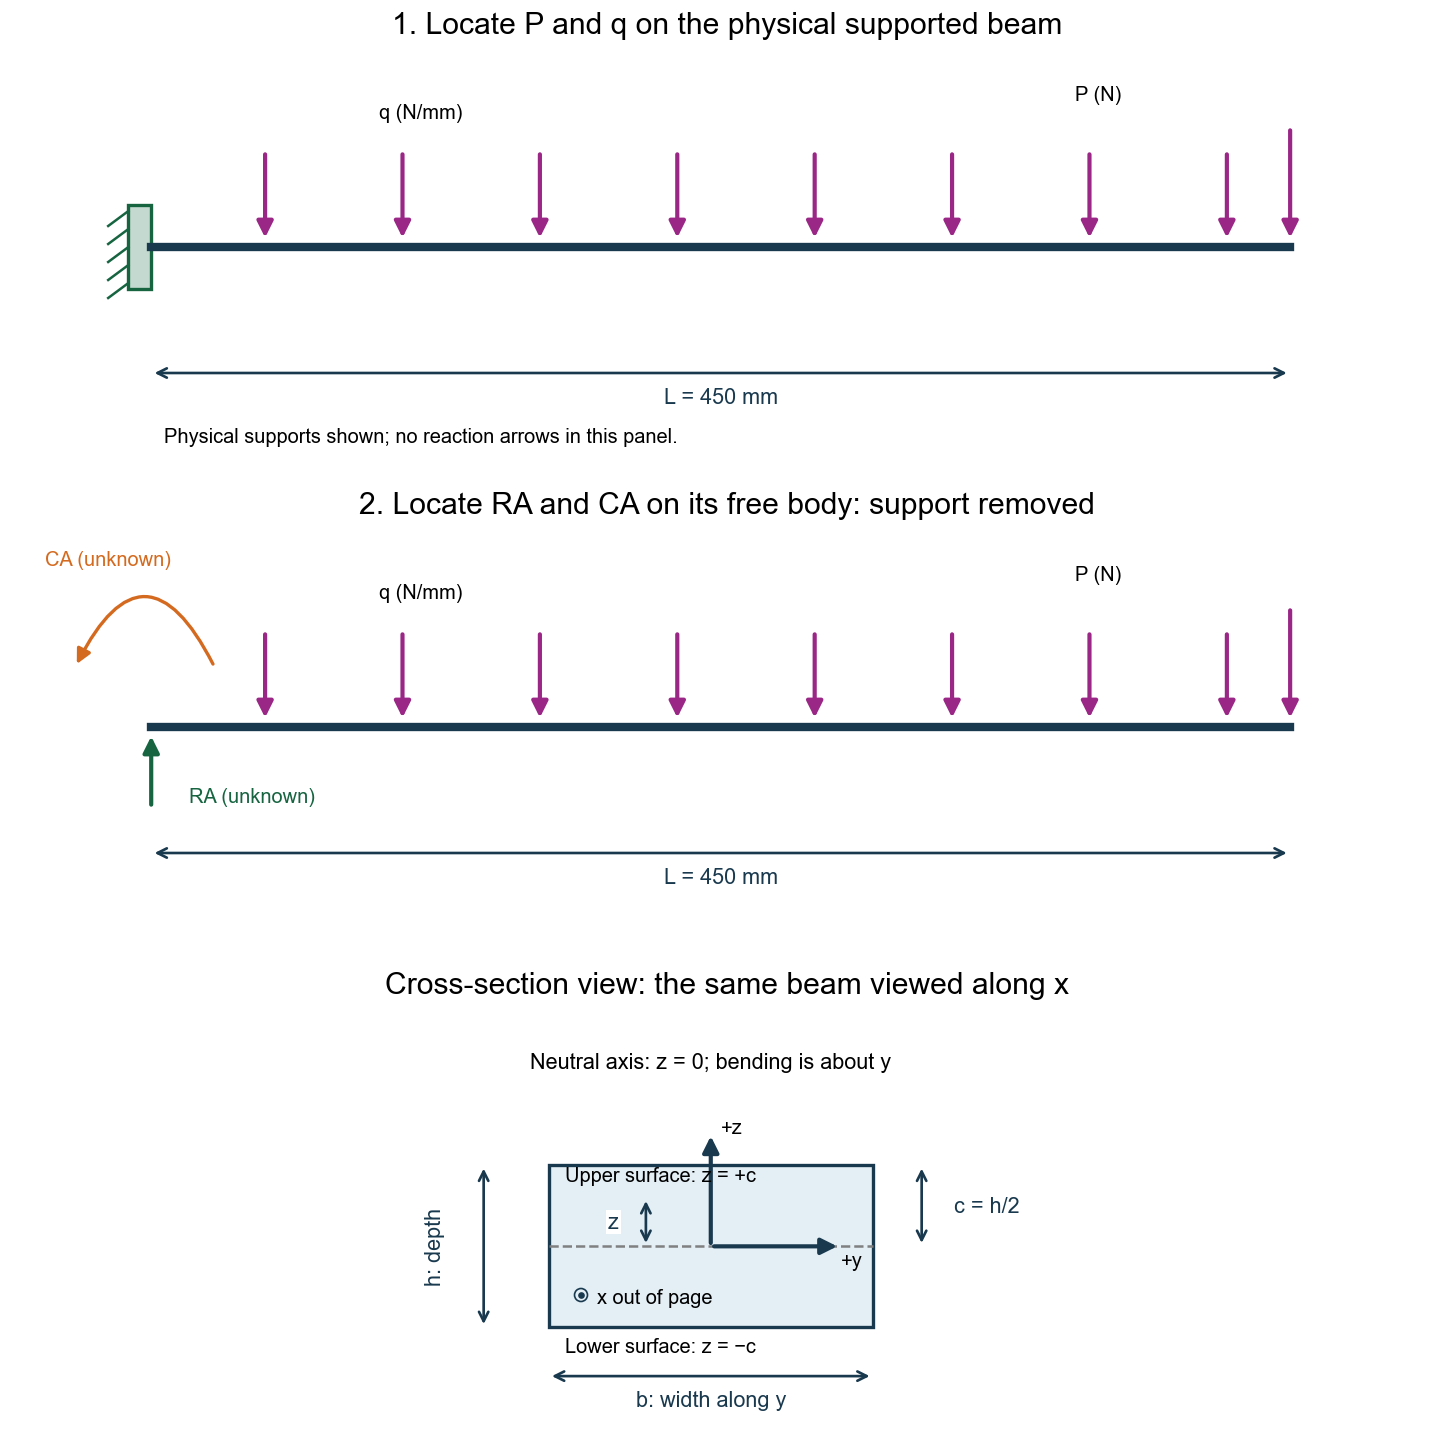

In [2]:
#@title Figure 0A — physical loads, their free body and section dimensions
fig,axes=plt.subplots(3,1,figsize=(12,12),layout='constrained')
beam_system_or_fbd(axes[0],'cantilever','1. Locate P and q on the physical supported beam',station=L,generic=True)
beam_system_or_fbd(axes[1],'cantilever','2. Locate RA and CA on its free body: support removed',station=L,generic=True,fbd=True)
ax=axes[2]

ax.add_patch(Rectangle((-10,-5),20,10,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.plot([-10,10],[0,0],'--',color='gray')
dimension(ax,(-10,-8),(10,-8),'b: width along y',(0,-1.5))
dimension(ax,(-14,-5),(-14,5),'h: depth',(-3,0),rotation=90)
dimension(ax,(13,0),(13,5),'c = h/2',(4,0))
dimension(ax,(-4,0),(-4,3),'z',(-2,0))
arrow(ax,(0,0),(0,7),'#19394e');ax.text(.6,7,'+z',fontsize=12)
arrow(ax,(0,0),(8,0),'#19394e');ax.text(8,-1.2,'+y',fontsize=12)
ax.add_patch(Circle((-8,-3),.4,fill=False,color='#19394e'));ax.plot(-8,-3,'.',color='#19394e')
ax.text(-7,-3.5,'x out of page',fontsize=12)
ax.text(-9,4,'Upper surface: z = +c',fontsize=12)
ax.text(-9,-6.5,'Lower surface: z = −c',fontsize=12)
ax.text(0,11,'Neutral axis: z = 0; bending is about y',ha='center',fontsize=13)
ax.set(xlim=(-22,24),ylim=(-12,15),title='Cross-section view: the same beam viewed along x')
ax.set_aspect('equal');ax.axis('off')

plt.show()

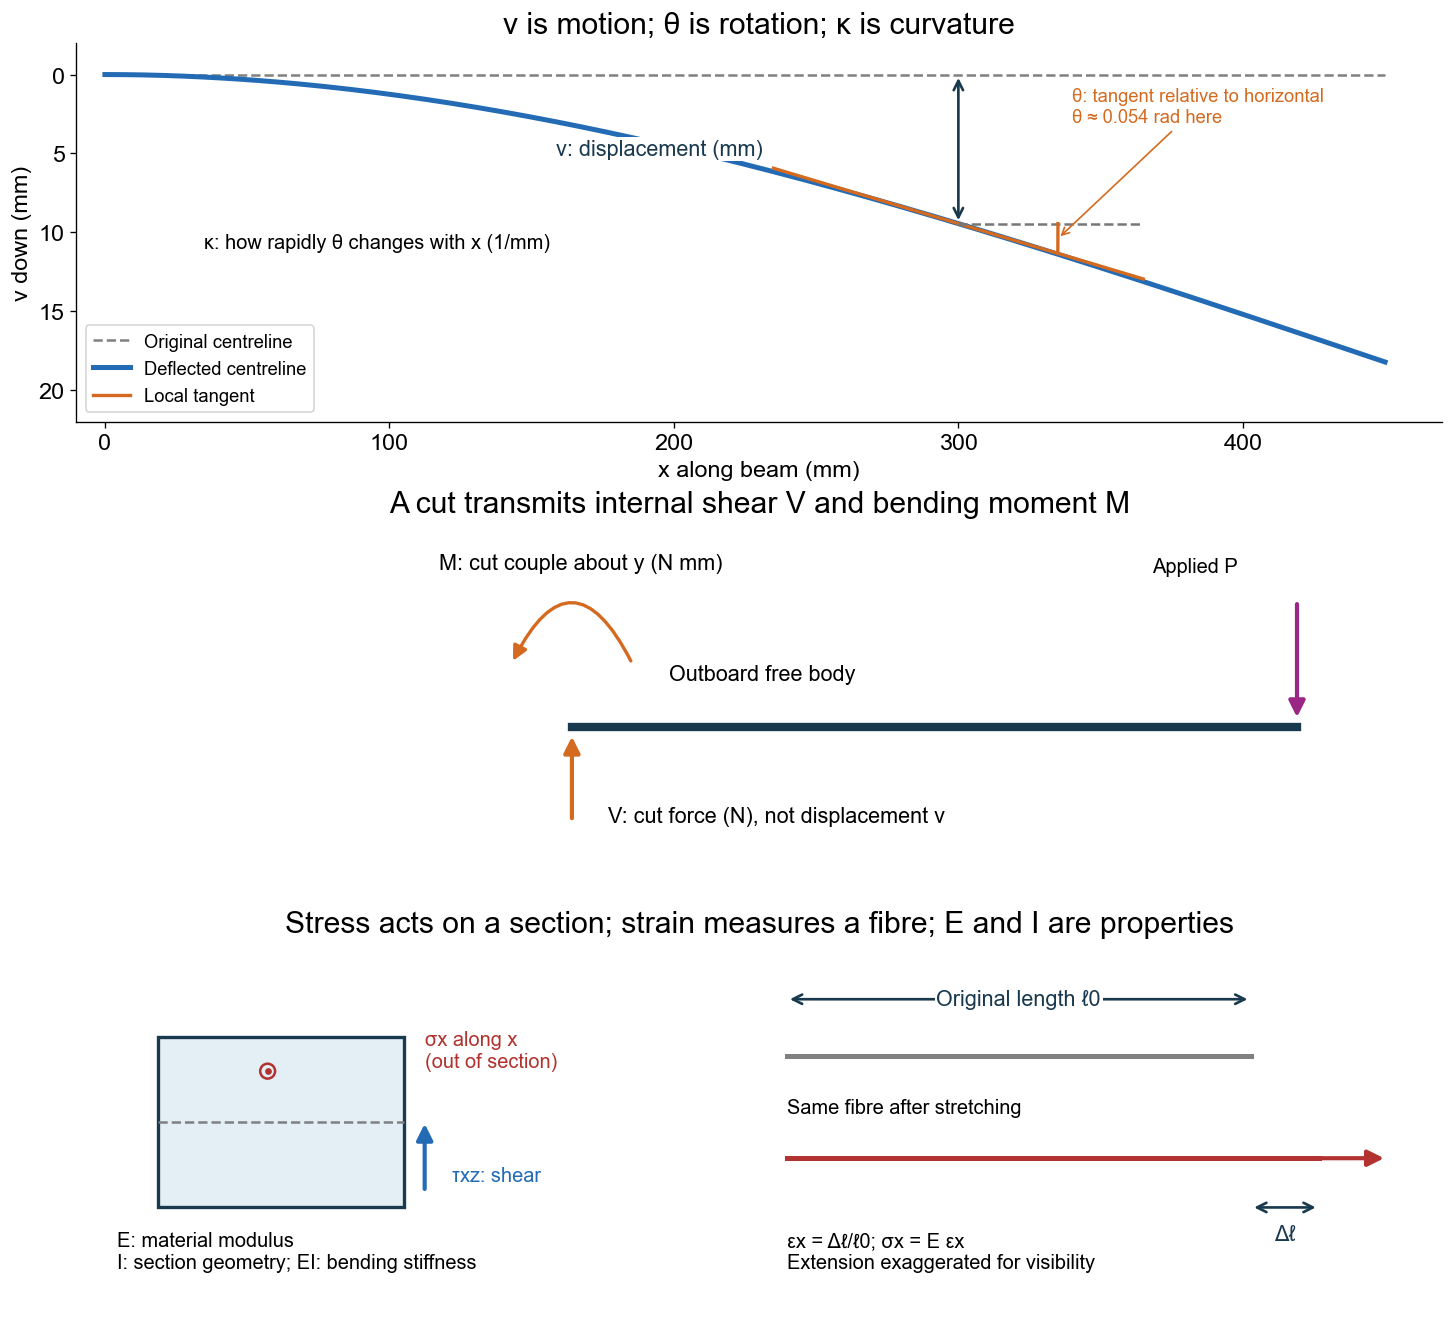

In [3]:
#@title Figure 0B — motion, internal actions and stress are different quantities
fig,axes=plt.subplots(3,1,figsize=(12,11),layout='constrained')
ax=axes[0]
xs=np.linspace(0,L,200); motion=P*xs**2*(3*L-xs)/(6*EI)
ax.plot(xs,np.zeros_like(xs),'--',color='gray',label='Original centreline')
ax.plot(xs,motion,color='#236bb4',lw=3,label='Deflected centreline')
at=300.; vt=P*at**2*(3*L-at)/(6*EI); slope=P*at*(2*L-at)/(2*EI)
ax.plot([at-65,at+65],[vt-65*slope,vt+65*slope],color='#d46a1f',lw=2,label='Local tangent')
ax.plot([at,at+65],[vt,vt],'--',color='#777777',lw=1.5)
aa=np.linspace(0,np.arctan(slope),50)
ax.plot(at+35*np.cos(aa),vt+35*np.sin(aa),color='#d46a1f',lw=2)
dimension(ax,(at,0),(at,vt),'v: displacement (mm)',(-105,0))
ax.annotate('θ: tangent relative to horizontal\nθ ≈ 0.054 rad here',
            xy=(at+35,vt+.95),xytext=(340,3),fontsize=11,color='#d46a1f',
            arrowprops=dict(arrowstyle='->',color='#d46a1f'))
ax.text(35,11,'κ: how rapidly θ changes with x (1/mm)',fontsize=12)
ax.set(xlim=(-10,470),ylim=(-2,22),title='v is motion; θ is rotation; κ is curvature')
ax.invert_yaxis();ax.set_xlabel('x along beam (mm)');ax.set_ylabel('v down (mm)');ax.legend(fontsize=11,loc='lower left')
ax=axes[1]
clean_beam(ax,'A cut transmits internal shear V and bending moment M')
ax.lines[0].remove();ax.plot([150,L],[0,0],lw=5,color='#19394e')
arrow(ax,(150,-30),(150,-2),'#d46a1f')
ax.text(165,-30,'V: cut force (N), not displacement v',fontsize=13)
ax.add_patch(FancyArrowPatch((175,20),(125,20),connectionstyle='arc3,rad=1',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(95,50,'M: cut couple about y (N mm)',fontsize=13)
arrow(ax,(L,40),(L,2));ax.text(390,49,'Applied P',fontsize=12)
ax.text(190,15,'Outboard free body',fontsize=13)
ax=axes[2];ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
ax.set_title('Stress acts on a section; strain measures a fibre; E and I are properties')
ax.add_patch(Rectangle((.06,.30),.18,.45,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.plot([.06,.24],[.525,.525],'--',color='gray')
ax.scatter([.14],[.66],s=80,facecolors='none',edgecolors='#b1322e',linewidths=1.5)
ax.plot(.14,.66,'.',color='#b1322e')
ax.text(.255,.67,'σx along x\n(out of section)',fontsize=12,color='#b1322e')
arrow(ax,(.255,.34),(.255,.53),'#236bb4')
ax.text(.275,.37,'τxz: shear',fontsize=12,color='#236bb4')
ax.text(.03,.14,'E: material modulus\nI: section geometry; EI: bending stiffness',fontsize=12)
ax.plot([.52,.86],[.70,.70],color='gray',lw=3)
ax.plot([.52,.91],[.43,.43],color='#b1322e',lw=3)
dimension(ax,(.52,.85),(.86,.85),'Original length ℓ0')
dimension(ax,(.86,.30),(.91,.30),'Δℓ',(0,-.07))
arrow(ax,(.91,.43),(.96,.43),'#b1322e')
ax.text(.52,.55,'Same fibre after stretching',fontsize=12)
ax.text(.52,.14,'εx = Δℓ/ℓ0; σx = E εx\nExtension exaggerated for visibility',fontsize=12)
plt.show()

### Reference table for the drawings above

**x** is distance along the beam, starting at the root. **z** is height in a cross-section, measured upward from its neutral axis. **y** is the transverse width direction. **v** is displacement downward, whereas **V** is the internal shear force. Neither is the flight speed in this lesson.

| Symbol | Meaning | Unit | Where it appears |
|---|---|---|---|
| L, x | Full length and cut station | mm | Side view |
| b, h | Section width and vertical depth | mm | Cross-section |
| c = h/2, z | Extreme-fibre distance and a selected fibre height | mm | Cross-section |
| P, q | Point force and distributed force per length | N, N/mm | Load drawing |
| Rₐ, Cₐ | Root force and root reaction couple | N, N mm | Whole-beam free body |
| V, M | Internal shear and signed sagging bending moment | N, N mm | A cut and diagrams |
| E, I, EI | Material modulus, second moment of area and bending stiffness | MPa, mm⁴, N mm² | Section and curvature calculation |
| εₓ, σₓ, τₓz | Longitudinal strain, longitudinal stress and transverse shear stress | dimensionless, MPa, MPa | Material fibres and stress profiles |
| v, θ, κ | Displacement, slope/rotation and curvature | mm, rad, 1/mm | Deflected beam |

Use the figure first, then the equation, then the numerical substitution. A subscript names a direction or station; it is not an extra multiplier. The figure dimensions are teaching inputs, not measured properties of the full course wing.

Figures 0A and 0B locate these symbols in views of the beam and its section. Figure 0A illustrates possible point and distributed loads; Example A below uses only the point force. Blue shows motion, purple shows applied loading, green shows support actions, and orange shows cut actions or a local tangent. Material properties and section stiffness are not extra applied forces.

## 1. What a support prevents and what it can transmit

A reaction is the force or moment that a support exerts to enforce a restricted motion. Do not draw a reaction moment at an ideal pin or roller: these allow rotation. A fixed support restricts rotation as well as translation.

| Ideal support in a planar model | Prevented motion | Reaction unknowns | Motion still allowed |
|---|---|---|---|
| Pin | Horizontal and vertical translation | R_x,R_z | Rotation |
| Roller on a horizontal surface | Vertical translation | R_z | Horizontal translation and rotation |
| Fixed clamp | Both translations and rotation | R_x,R_z,M_A | None at the support |
| Free end | None | No support reaction | Translation and rotation |

These are idealizations, not descriptions of every bolt or bearing. A real wing attachment uses multiple fittings to transmit forces and a couple. In our **transverse-bending app**, only displacement v and slope θ are solved: axial displacement is not a degree of freedom. Under purely transverse loading the planar horizontal reaction is zero, not an additional solved app result.

For a whole planar free body:

$$\sum F_x=0,\qquad \sum F_z=0,\qquad \sum M=0.$$

A pin–roller beam has three planar reaction unknowns and three equilibrium equations. Two fixed ends have six planar unknowns: equilibrium alone is insufficient. In transverse bending, four reactions (R_A,M_A,R_B,M_B) need two equilibrium equations **plus displacement/rotation compatibility and stiffness**. Here no axial load is applied; the separate axial redundancy is outside the transverse model.

**How to draw a reaction:** imagine the support removed, leaving only the beam. Replace each motion that was prevented by a possible force or couple. Initially assume a direction; a negative solution means the real direction is opposite. The fixed support requires a couple because it prevents the end section rotating. A pin lets that section rotate, so an ideal pin has no reaction couple.

For our transverse cantilever, two nonzero reaction unknowns are enough: the vertical root force and the root couple. Taking moments about the root removes the root force from that equation because its lever arm is zero. For a pin–roller beam, taking moments about A first determines the reaction at B; vertical equilibrium then determines A.

## 2. Calculate support reactions under the same load

Use L = 450 mm and P = 2 N downward at a = L/2 = 225 mm in all three comparison drawings. Hand free bodies use upward forces and counterclockwise (CCW) couples as positive. The app uses downward force and clockwise couples as positive, so its reaction signs are reversed.

**These are external support reactions.** Internal section moment M later uses the separate sagging-positive convention. Do not replace the signs of support couples by signs from the internal-moment diagram.

**Two drawings, two roles:** first draw the supported physical system with applied loads only. Next isolate the same beam, remove every support symbol and replace it by the relevant reaction force/couple. Keep the applied loads on that free body. Equilibrium equations below the pair refer to the second drawing. A load-only drawing is not a complete free body.

### 2A. One fixed end — centre load

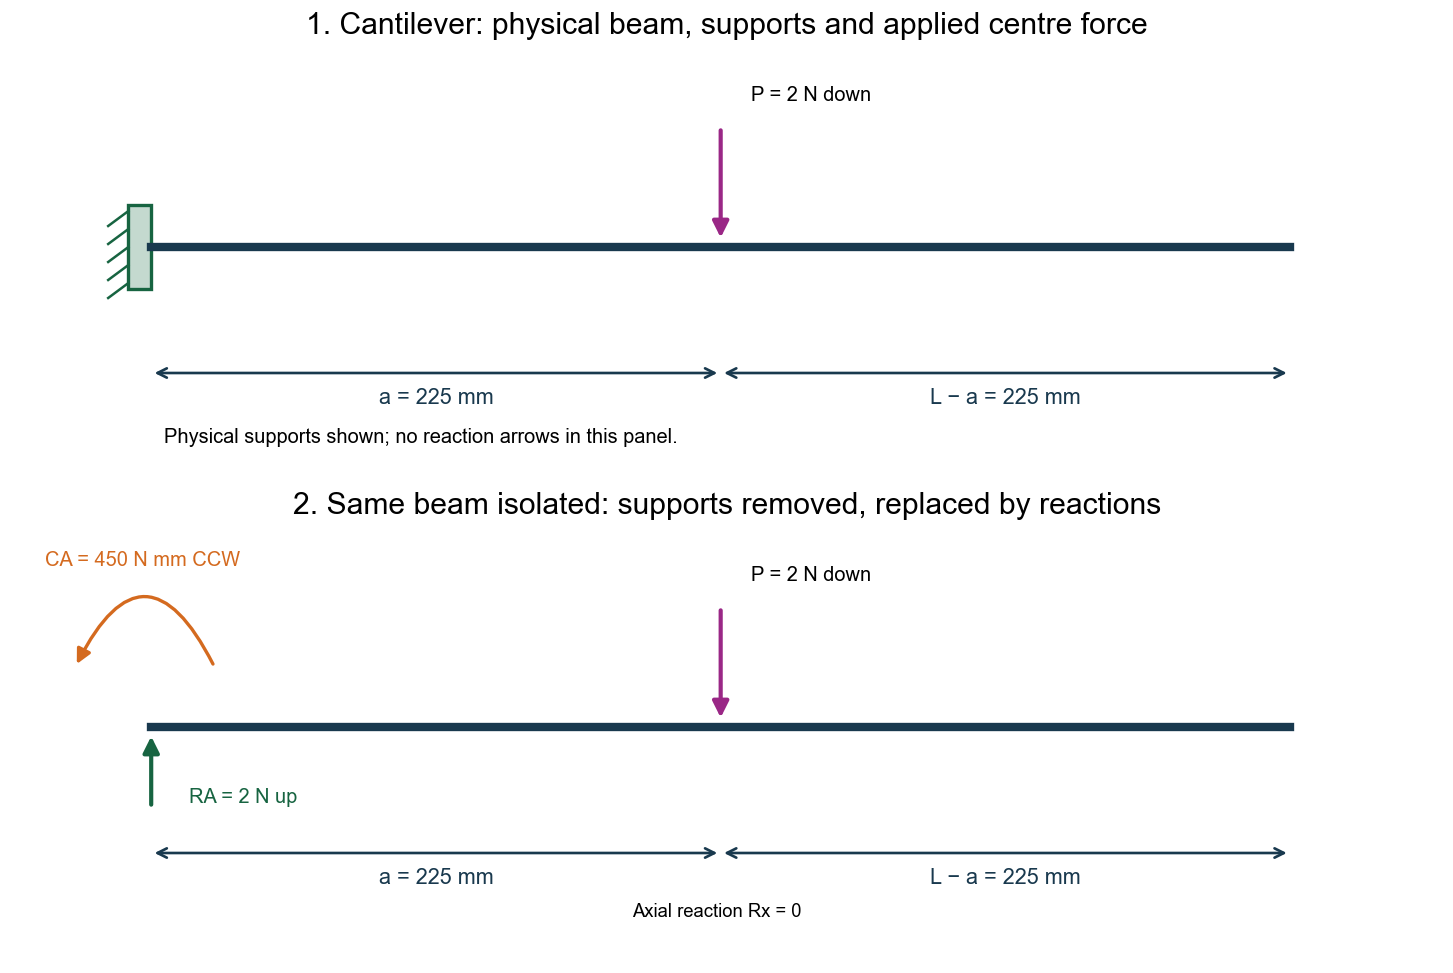

In [4]:
#@title Figure 1A — supported system first, free body second
fig,axes=plt.subplots(2,1,figsize=(12,8),layout='constrained')
beam_system_or_fbd(axes[0],'cantilever','1. Cantilever: physical beam, supports and applied centre force')
beam_system_or_fbd(axes[1],'cantilever','2. Same beam isolated: supports removed, replaced by reactions',fbd=True)
plt.show()

The free end is not a support, so it contributes no reaction. At A, horizontal force balance gives Rₓ = 0. Vertical balance and moments about A give:

$$\sum F_z=0:\quad R_A-2=0\quad\Longrightarrow R_A=2\ \mathrm{N\ upward},$$

$$\sum M_A=0:\quad C_A-2(225)=0\quad\Longrightarrow C_A=450\ \mathrm{N\,mm\ CCW}.$$

There are two transverse reaction unknowns and two equilibrium equations. The app reports −2 N and −450 N mm. Changing the load station changes its moment arm, not the number of reaction unknowns.

**[Open this exact beam study: cantilever with the 2 N centre force](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-centre)**. The link replaces the old study with these inputs and solves it.

#### Example A belongs to this cantilever — move the same force to the tip

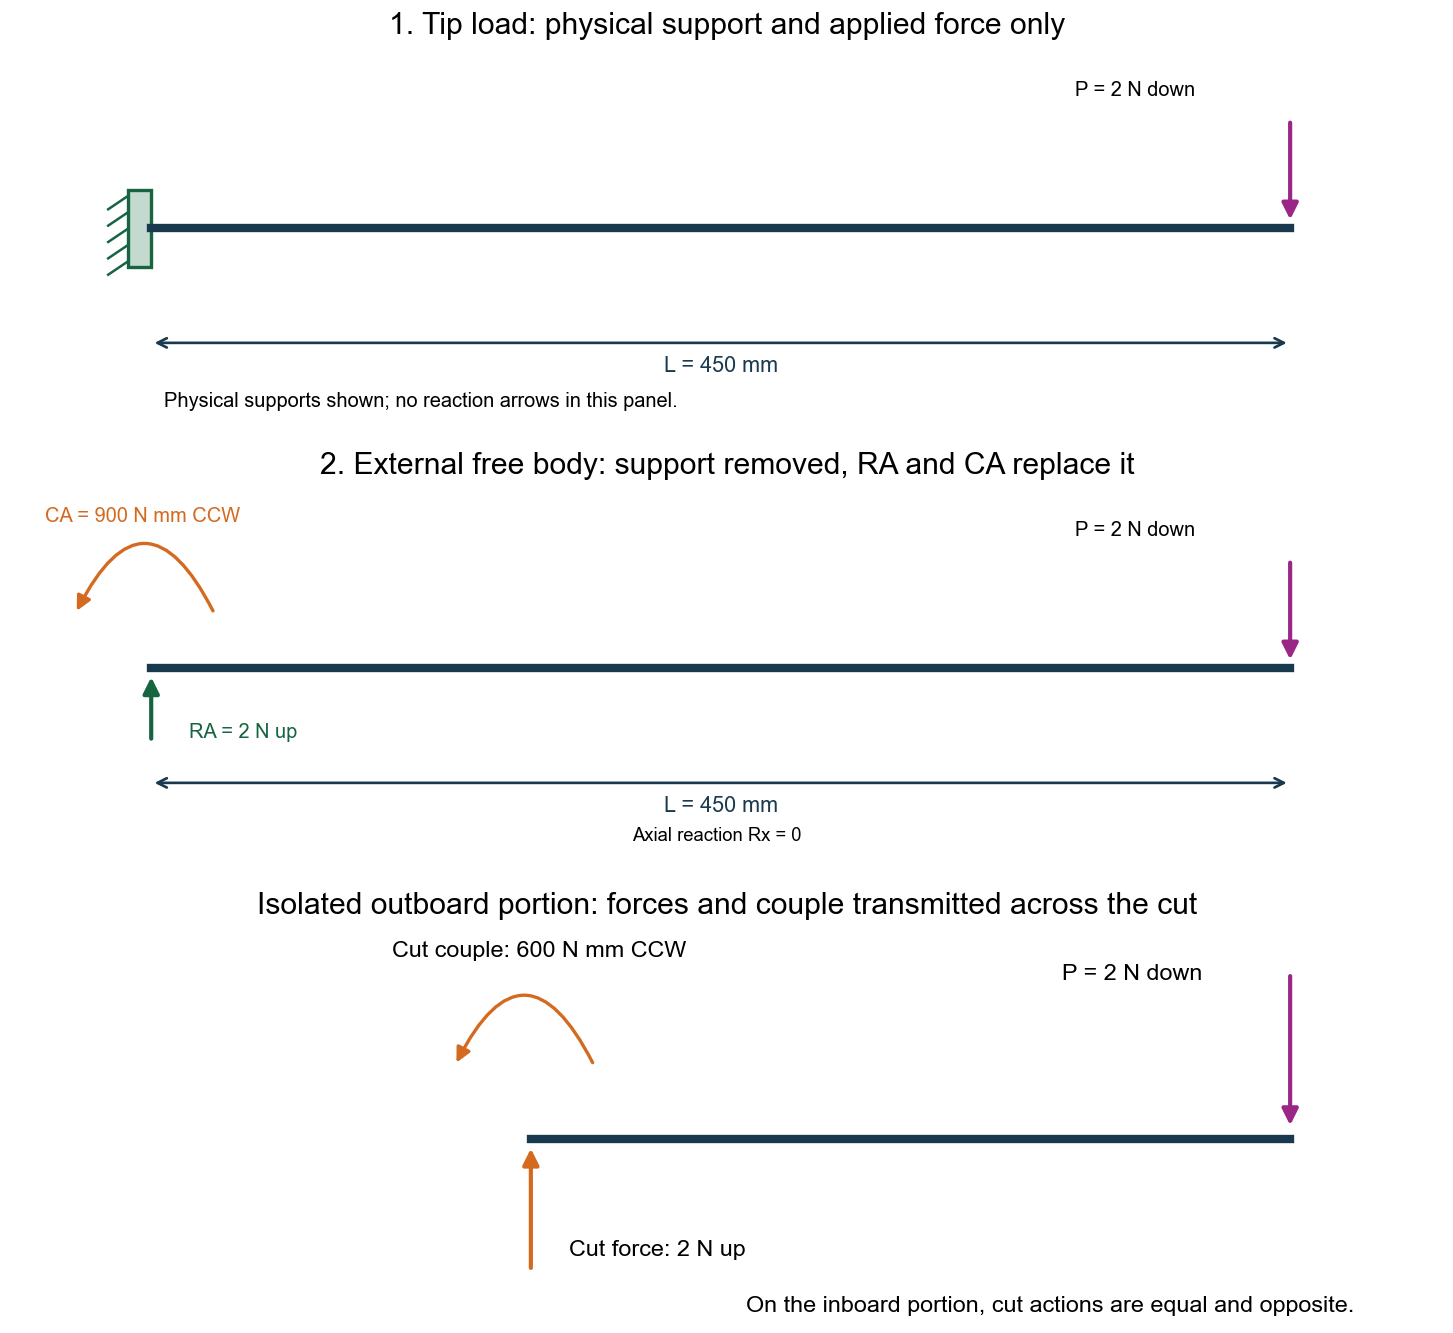

In [5]:
#@title Figure 2 — physical tip-load system, external free body, isolated cut
fig,panels=plt.subplots(3,1,figsize=(12,11),layout='constrained')
beam_system_or_fbd(panels[0],'cantilever','1. Tip load: physical support and applied force only',station=L)
beam_system_or_fbd(panels[1],'cantilever','2. External free body: support removed, RA and CA replace it',station=L,fbd=True)
ax=panels[2]

clean_beam(ax,'Isolated outboard portion: forces and couple transmitted across the cut')
ax.lines[0].remove()
ax.plot([150,L],[0,0],color='#19394e',lw=5)
arrow(ax,(L,50),(L,3)); ax.text(360,48,'P = 2 N down')
arrow(ax,(150,-40),(150,-2),'#d46a1f'); ax.text(165,-35,'Cut force: 2 N up')
ax.add_patch(FancyArrowPatch((175,22),(120,22),connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(95,55,'Cut couple: 600 N mm CCW')
ax.text(235,-52,'On the inboard portion, cut actions are equal and opposite.')

plt.show()

This drawing now has a = L = 450 mm. The applied force is unchanged, but its lever arm doubles:

$$R_A-P=0,\qquad C_A-PL=0.$$

Thus Rₐ = 2 N upward and Cₐ = 900 N mm CCW. The app gives −2 N and −900 N mm. At the cut x = 150 mm, the remaining arm is 300 mm and the cut couple magnitude is 600 N mm. These are the actions shown on the separate outboard free body.

**[Open this exact beam study: Example A: 2 N at the free tip](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-tip)**. The link replaces the old study with these inputs and solves it.

#### Example B belongs to this cantilever — spread the same 2 N along the span

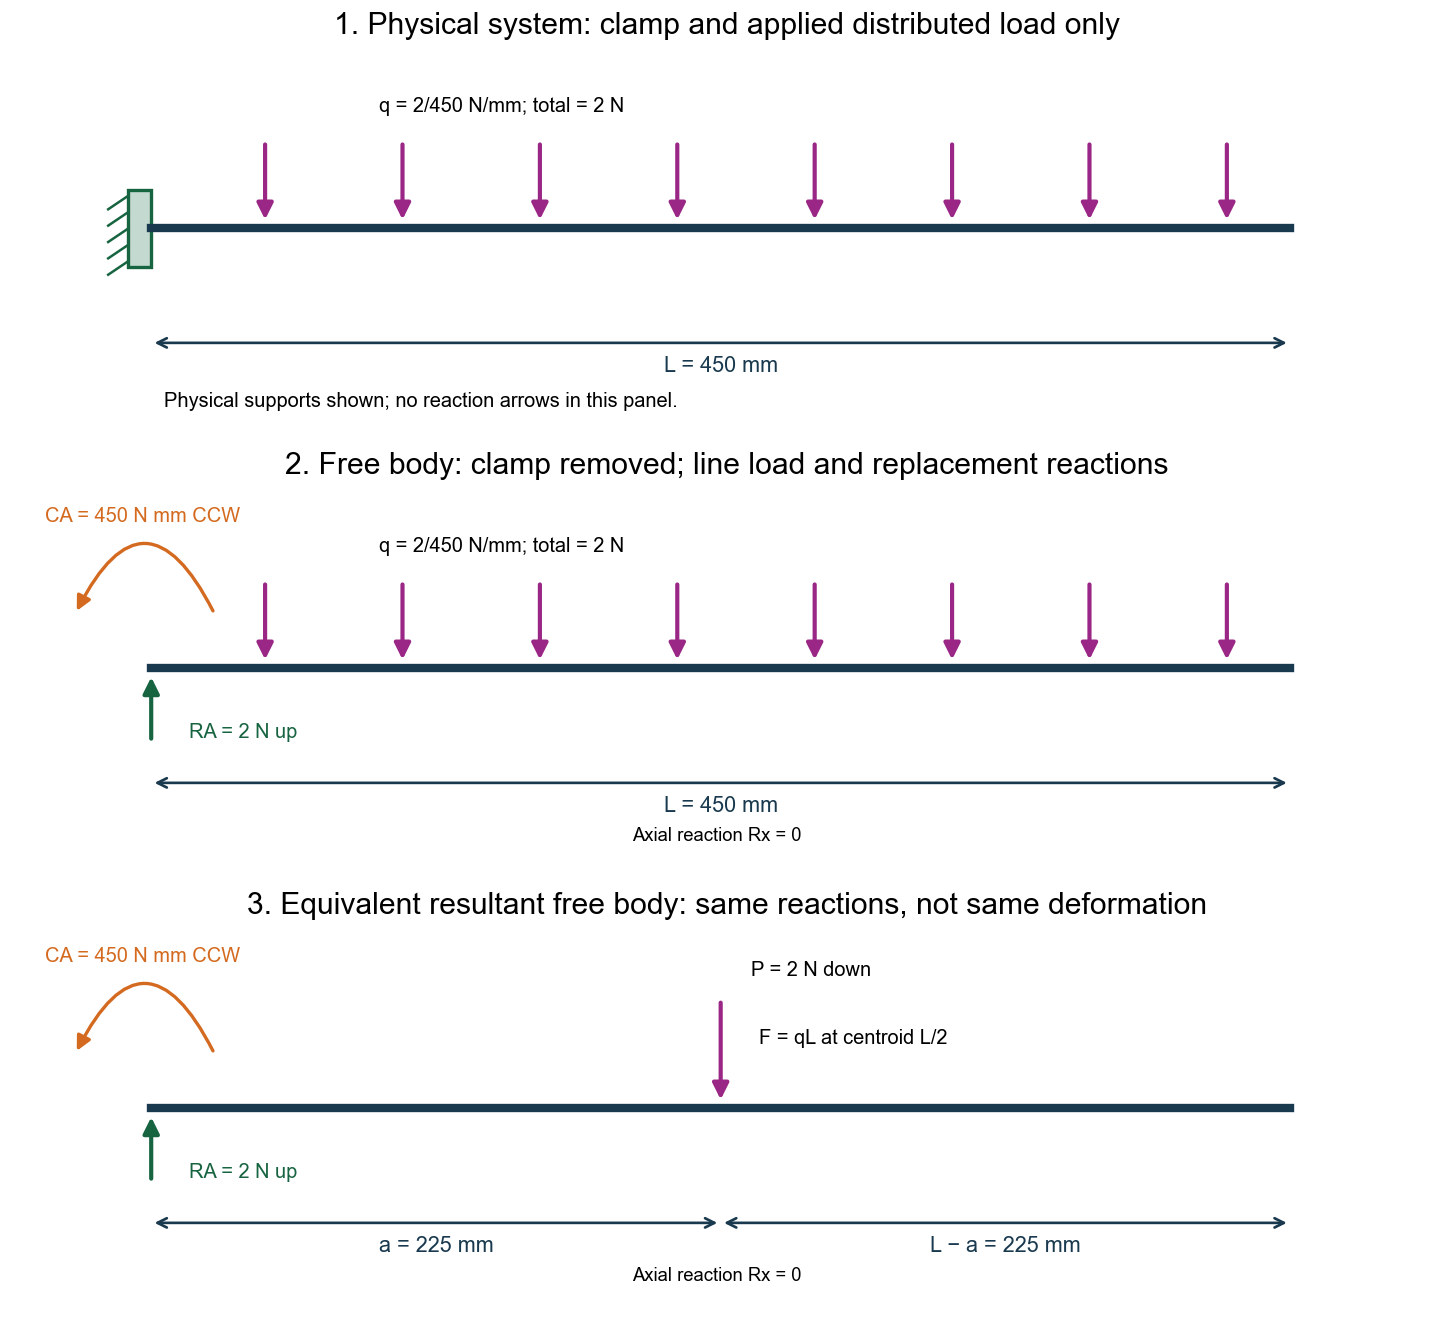

In [6]:
#@title Figure 6A — uniform-load system and two valid free-body representations
fig,axes=plt.subplots(3,1,figsize=(12,11),layout='constrained')
beam_system_or_fbd(axes[0],'cantilever','1. Physical system: clamp and applied distributed load only',uniform=True)
beam_system_or_fbd(axes[1],'cantilever','2. Free body: clamp removed; line load and replacement reactions',uniform=True,fbd=True)
beam_system_or_fbd(axes[2],'cantilever','3. Equivalent resultant free body: same reactions, not same deformation',station=L/2,fbd=True)
axes[2].text(240,24,'F = qL at centroid L/2',fontsize=12)
plt.show()

For a uniform line load q = 2/450 = 0.00444444 N/mm, the area under q is F = qL = 2 N. Its centroid lies at L/2:

$$R_A-qL=0,\qquad C_A-(qL)\frac{L}{2}=0.$$

Therefore Rₐ = 2 N upward and Cₐ = 450 N mm CCW. The centre point-load and uniform-load cases have the same whole-beam reactions, but not the same internal distributions or displacement. Replacing a distributed load by its resultant preserves whole-beam equilibrium, not the entire response.

**[Open this exact beam study: Example B: uniform downward load totalling 2 N](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-uniform)**. The link replaces the old study with these inputs and solves it.

**[Open this exact beam study: same uniform magnitude directed upward, a lift analogue](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-lift)**. The link replaces the old study with these inputs and solves it.

### 2B. Pin and roller — the same centre force

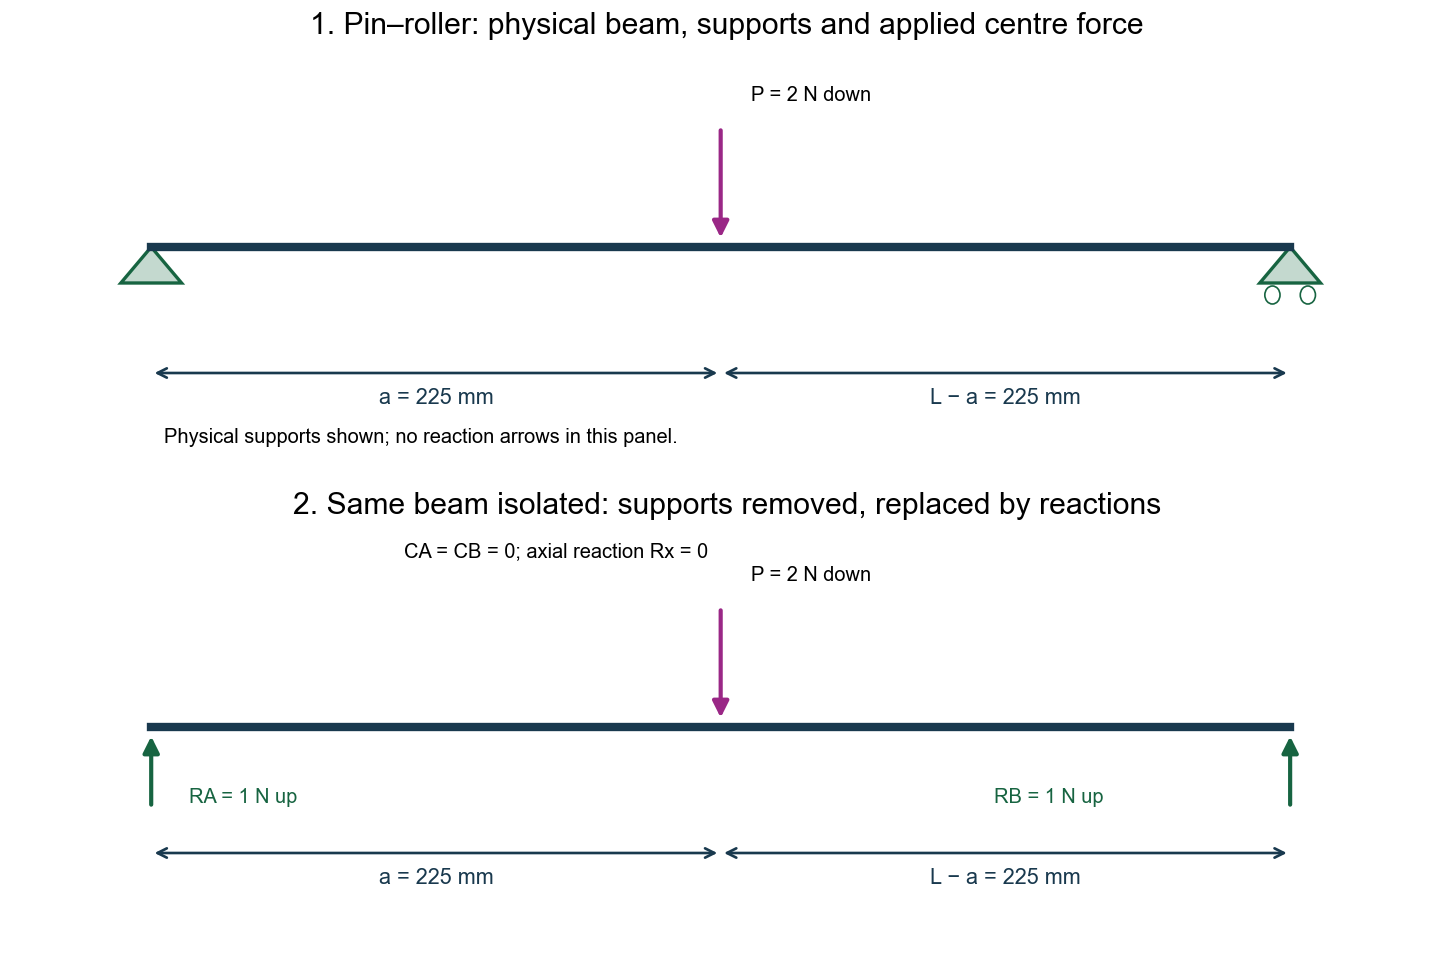

In [7]:
#@title Figure 1B — supported system first, free body second
fig,axes=plt.subplots(2,1,figsize=(12,8),layout='constrained')
beam_system_or_fbd(axes[0],'simple','1. Pin–roller: physical beam, supports and applied centre force')
beam_system_or_fbd(axes[1],'simple','2. Same beam isolated: supports removed, replaced by reactions',fbd=True)
plt.show()

The pin supplies horizontal/vertical force, but no couple. A horizontal roller supplies vertical force only. Thus Rₓ = 0 and Cₐ = Cᵦ = 0. Take moments about A first:

$$R_A+R_B-2=0,$$

$$R_B(450)-2(225)=0\quad\Longrightarrow R_B=1\ \mathrm{N\ upward}.$$

Then Rₐ = 2 − 1 = 1 N upward. Two transverse unknowns are found from equilibrium; no material modulus is needed. The app reports −1 N at each support and zero couples.

**[Open this exact beam study: pin–roller with the 2 N centre force](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-simple)**. The link replaces the old study with these inputs and solves it.

### 2C. Both ends fixed — the same centre force

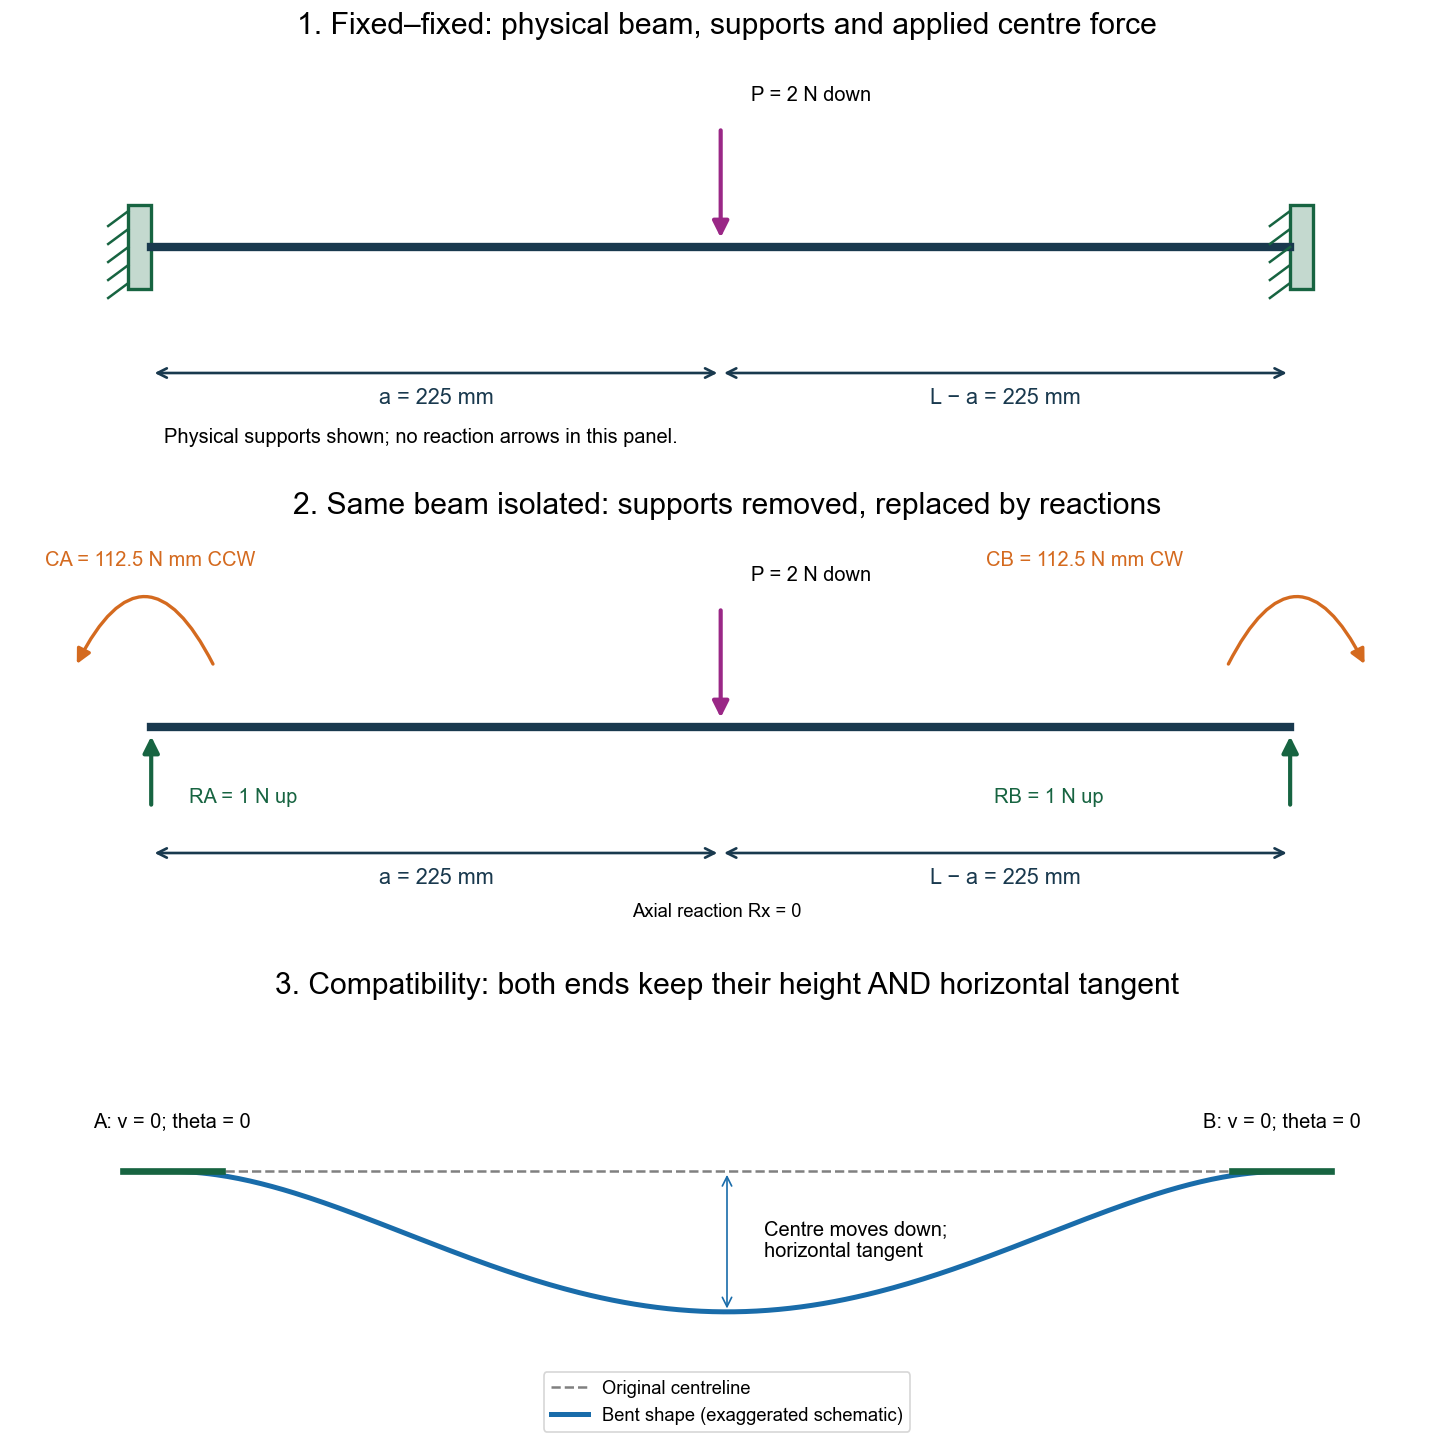

In [8]:
#@title Figure 1C — supported system first, free body second
fig,axes=plt.subplots(3,1,figsize=(12,12),layout='constrained')
beam_system_or_fbd(axes[0],'fixed','1. Fixed–fixed: physical beam, supports and applied centre force')
beam_system_or_fbd(axes[1],'fixed','2. Same beam isolated: supports removed, replaced by reactions',fbd=True)

ax=axes[2]
xx=np.linspace(0,L,301)
shape=-25*16*(xx/L)**2*(1-xx/L)**2
ax.plot(xx,np.zeros_like(xx),'--',color='gray',label='Original centreline')
ax.plot(xx,shape,color='#196caa',lw=3,label='Bent shape (exaggerated schematic)')
for end,label in [(0,'A'),(L,'B')]:
    ax.plot([end-20,end+20],[0,0],color='#176441',lw=4)
    ax.text(end,8,label+': v = 0; theta = 0',ha='center',fontsize=12)
ax.annotate('',xy=(L/2,-25),xytext=(L/2,0),arrowprops=dict(arrowstyle='<->',color='#196caa'))
ax.text(L/2+15,-15,'Centre moves down;\nhorizontal tangent',fontsize=12)
ax.set(xlim=(-65,L+65),ylim=(-48,30))
ax.set_title('3. Compatibility: both ends keep their height AND horizontal tangent')
ax.axis('off');ax.legend(loc='lower center',fontsize=11)
plt.show()

Both supports prevent translation and rotation. There are four transverse unknowns: Rₐ, Rᵦ, Cₐ and Cᵦ. Whole-beam equilibrium gives:

$$R_A+R_B-2=0,$$

$$C_A+C_B+450R_B-2(225)=0.$$

#### Why do we need two more equations?

Equilibrium says that the beam does not accelerate; it does **not** say whether its bent shape fits its supports. Four transverse reactions but only two equilibrium equations leave two unknowns undetermined. This is a **statically indeterminate beam of degree two** in the transverse bending model. Axial reactions are outside this model.

**Compatibility means that the deformed beam must still fit the supports.** A perfect clamp does not let the end move vertically or rotate. Therefore v(0) = 0, θ(0) = 0, v(L) = 0 and θ(L) = 0. The centre may move downward; a clamp does not mean the whole beam stays straight.

We build the shape starting at A with v(0) = θ(0) = 0. The **two additional requirements at B** are:

$$\boxed{\theta(L)=0}\qquad\boxed{v(L)=0}.$$

The first says “the right end must finish horizontal”; the second says “the right end must finish at its original height.” These are geometric conditions, not extra force balances. If guessed reactions leave a tilted or vertically displaced right end, they cannot be the reactions of this fixed–fixed beam.

#### How do these geometric conditions become equations for reactions?

For small elastic bending, moment makes curvature. With v positive downward and M positive in sagging, our sign convention gives:

$$\theta=\frac{dv}{dx},\qquad \frac{d\theta}{dx}=-\frac{M(x)}{EI}.$$

Think of a tiny length dx: curvature changes its slope by −M dx/(EI). Adding all these slope changes gives the end rotation. Adding slopes along the beam gives displacement. Section 5 derives this material/geometry relation more fully. For constant EI and the zero starting displacement and rotation at A:

$$\boxed{\theta(L)=-\frac{1}{EI}\int_0^L M(x)\,dx=0}$$

$$\boxed{v(L)=-\frac{1}{EI}\int_0^L (L-x)M(x)\,dx=0}$$

Why the factor L − x? A small change of slope created at station x contributes displacement over the remaining distance to B. The first integral has units of rotation (dimensionless, reported in radians); the second has units of length. Positive and negative moment regions must cancel in the required ways.

For a point force at a = L/2, a cut of the left portion gives:

$$M(x)=
\begin{cases}
-C_A+R_Ax,&0\leq x<a,\\
-C_A+R_Ax-P(x-a),&a\leq x\leq L.
\end{cases}$$

The load contributes only after the cut passes its location. Substituting this piecewise moment into the two compatibility integrals gives two simple algebraic equations:

$$\boxed{-C_A L+\frac{R_A L^2}{2}-\frac{P(L-a)^2}{2}=0}$$

$$\boxed{-\frac{C_A L^2}{2}+\frac{R_A L^3}{6}-\frac{P(L-a)^3}{6}=0}.$$

These are **zero rotation and zero displacement**, respectively—not new laws of equilibrium. The common nonzero EI cancels because it is constant here. It cannot generally be taken outside the integral for a tapered or variable-stiffness beam.

#### Solve the two equations, then return to equilibrium

For L = 450 mm, a = 225 mm and P = 2 N:

$$-450C_A+101250R_A-50625=0,$$

$$-101250C_A+15187500R_A-3796875=0.$$

Multiply the first equation by L/2 = 225 mm and subtract the second. This gives Rₐ = 1 N. Substitution in the first gives Cₐ = 112.5 N mm CCW. Equilibrium then gives Rᵦ = 1 N and Cᵦ = −112.5 N mm (clockwise). Equal vertical reactions are also an independent symmetry check.

$$C_A=\frac{PL}{8}=112.5\ \mathrm{N\,mm\ CCW},\qquad C_B=-112.5\ \mathrm{N\,mm\ CW}.$$

**Check the shape, not only the forces:** these reactions give θ(L) = 0 and v(L) = 0, while the centre displacement is PL³/(192EI) = 0.2848 mm downward. The midpoint tangent is horizontal by symmetry, but the midpoint displacement is not zero.

**Today's method:** equilibrium + elastic bending + compatibility. **Lecture 04 will use virtual work to solve this type of beam**; no virtual-work calculation is required here.

Substitution into the whole-beam moment equation gives 112.5 − 112.5 + 450 − 450 = 0 N mm. The app reports −112.5 at A and +112.5 at B because its positive couple direction is clockwise. Both **internal** end moments are −112.5 N mm; that is a different sign convention on different cut faces. The displacement/curvature relation used here is explained geometrically in Section 5.

**[Open this exact beam study: fixed–fixed with the 2 N centre force](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-fixed)**. The link replaces the old study with these inputs and solves it.

### Compare reactions before comparing stress or displacement

| Same 2 N centre load | Vertical reactions | External support couples | What found them? |
|---|---|---|---|
| Cantilever | A: 2 N upward | A: 450 N mm CCW; none at free B | Equilibrium |
| Pin–roller | A and B: 1 N upward each | Both zero | Equilibrium |
| Fixed–fixed | A and B: 1 N upward each | A: 112.5 CCW; B: 112.5 CW | Equilibrium plus compatibility |

A stronger constraint does not remove the load. It changes how forces and couples are shared. For a real aircraft root, multiple fittings collectively transmit the bending couple; a drawn clamp is their idealization.

## 3. A cut reveals the internal shear and moment

Isolate the portion to the right of a cut at x. The tip force still acts on it. The cut must supply a shear force and bending moment to balance that portion. **Internal forces are not additional applied loads:** on opposite cut faces they form equal-and-opposite pairs.

Use the app convention throughout the following diagrams: downward load q and deflection v positive; positive internal M is sagging; z positive upward from the neutral axis.

$$V(x)=P,\qquad M(x)=-P(L-x),\qquad 0<x<L.$$

At (x=150) mm, (V=2) N and (M=-600) N mm. At the root-side section, M=-900 N mm. At the tip, (M=0). Shear has a jump at a point force; do not interpret a vertical jump as a finite-length triangular load.

For a distributed downward-positive load:

$$\frac{dV}{dx}=-q(x),\qquad \frac{dM}{dx}=V(x).$$

In words: load changes the shear; shear changes the moment. A constant shear produces a straight-line moment diagram.

### Calculate at a cut rather than memorize a diagram

At x = 150 mm the outboard portion is 300 mm long. Its 2 N tip load produces a 600 N mm clockwise external turning effect about the cut. The cut therefore supplies 2 N upward and a 600 N mm counterclockwise couple to that outboard portion. These are the physical arrows in Figure 2. With the app's internal sagging-positive convention, the reported section values are V = +2 N and M = −600 N mm.

| Cut station x | Remaining lever arm L − x | V | M = −P(L − x) |
|---:|---:|---:|---:|
| 0 mm, just inside the root | 450 mm | +2 N | −900 N mm |
| 150 mm | 300 mm | +2 N | −600 N mm |
| 300 mm | 150 mm | +2 N | −300 N mm |
| 450 mm, just inside the tip | 0 mm | +2 N | 0 N mm |

The derivative relations are local equilibrium statements. Over a short distance Δx, downward distributed load qΔx decreases V by approximately qΔx. Moment changes by approximately VΔx. Therefore a uniform q gives a linear V diagram and a curved, quadratic M diagram; with no line load between root and tip, V is constant.

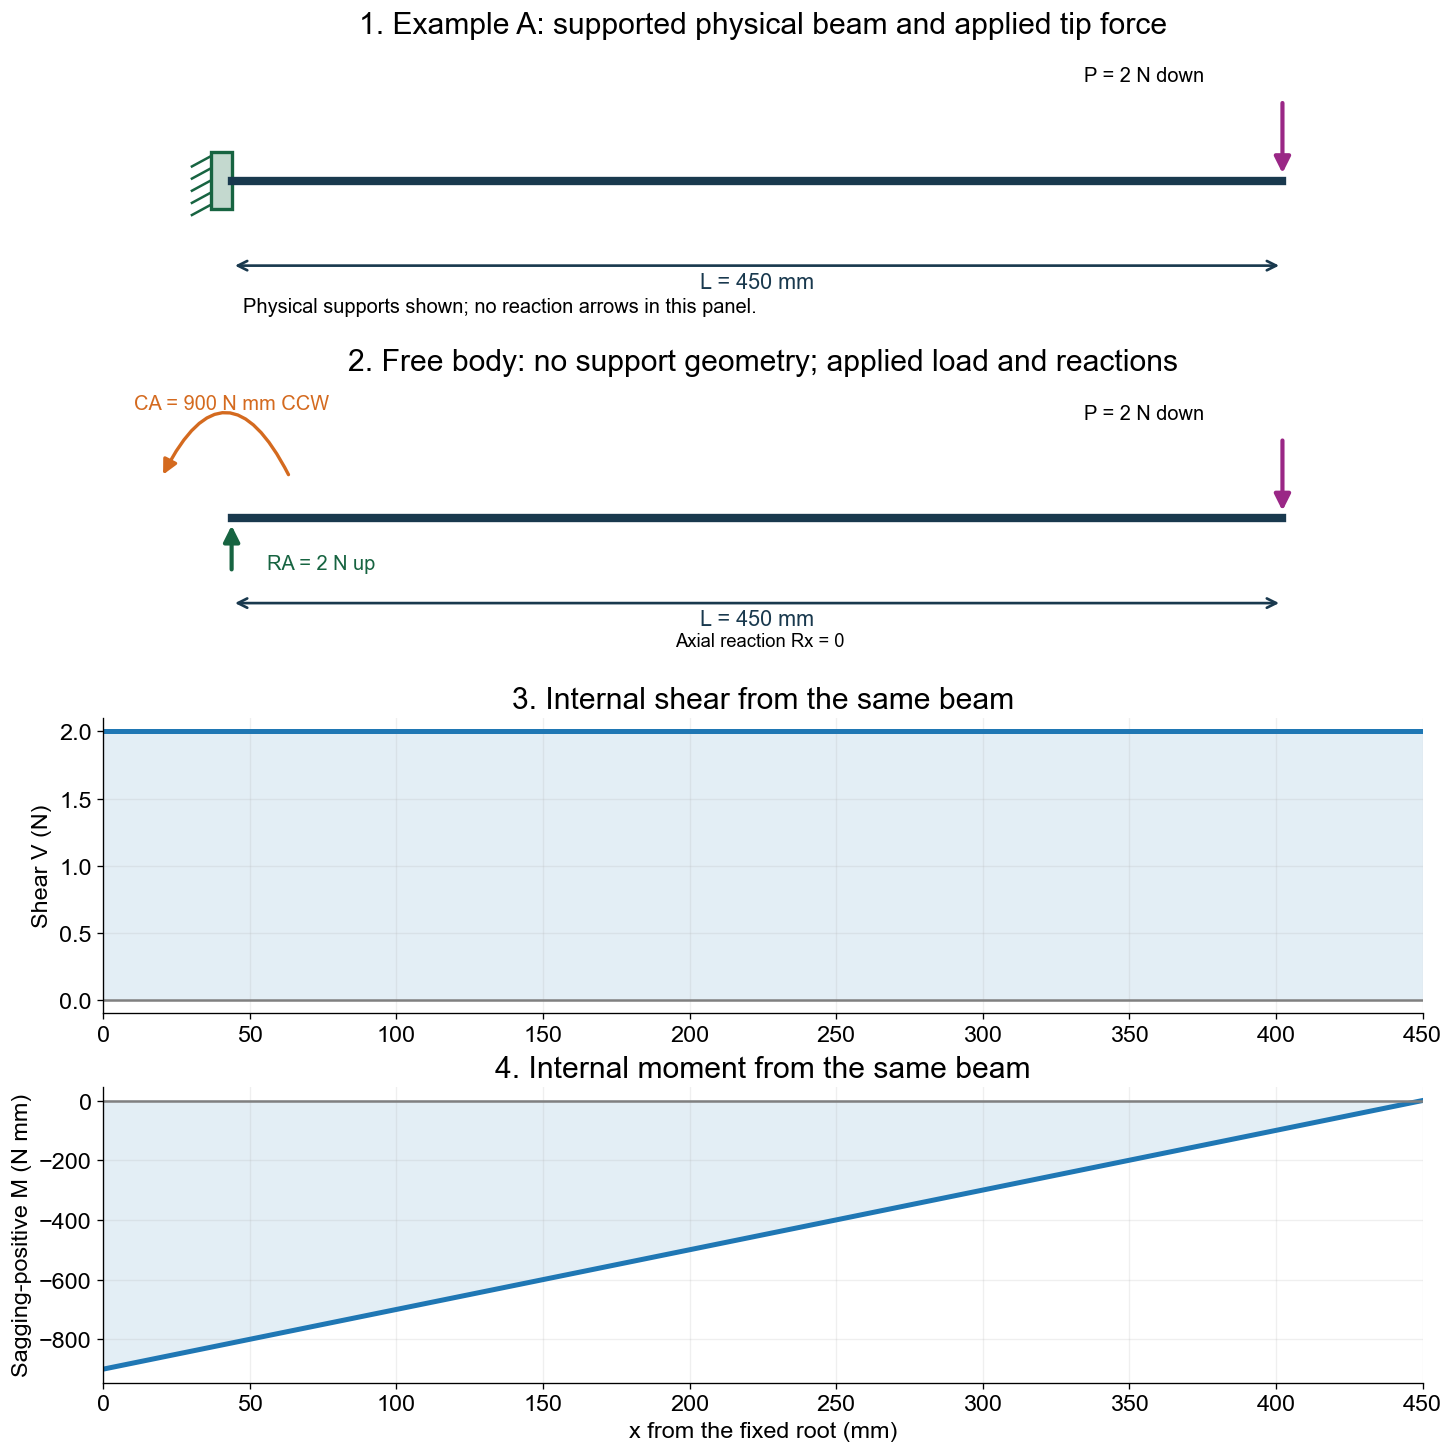

In [9]:
#@title Figure 3 — physical beam, its free body, then V and M diagrams
V=np.full_like(x,P);M=-P*(L-x)
fig,axes=plt.subplots(4,1,figsize=(12,12),layout='constrained')
beam_system_or_fbd(axes[0],'cantilever','1. Example A: supported physical beam and applied tip force',station=L)
beam_system_or_fbd(axes[1],'cantilever','2. Free body: no support geometry; applied load and reactions',station=L,fbd=True)
for ax,yy,label in zip(axes[2:],[V,M],['Shear V (N)','Sagging-positive M (N mm)']):
    ax.plot(x,yy,lw=3);ax.fill_between(x,yy,0,alpha=.12)
    ax.axhline(0,color='gray');ax.set_ylabel(label);ax.grid(alpha=.2);ax.set_xlim(0,L)
axes[2].set_title('3. Internal shear from the same beam')
axes[3].set_title('4. Internal moment from the same beam')
axes[3].set_xlabel('x from the fixed root (mm)')
plt.show()

## 4. Learn stress before using the beam stress equation

### 4.1. Force across a small surface

Imagine cutting through material and examining a small surface patch of area ΔA. The material on the other side transmits a force ΔF across that patch. **Traction** is the force vector per surface area:

$$\mathbf t(\mathbf n)=\lim_{\Delta A\to0}\frac{\Delta\mathbf F}{\Delta A}.$$

The unit normal n identifies which surface is being examined. Resolve this force into a component perpendicular to that face and components tangent to it:

$$\sigma_n=\frac{F_n}{A},\qquad \tau=\frac{F_t}{A}\quad\text{for uniform components over an area}.$$

**Normal stress means perpendicular to the face**, not necessarily vertical in the room. On a beam cross-section normal to x, normal stress σₓₓ acts along the beam. A force parallel to that face produces shear stress. N/mm² is MPa. The average F/A does not tell us whether stress is uniform: bending produces a varying distribution.

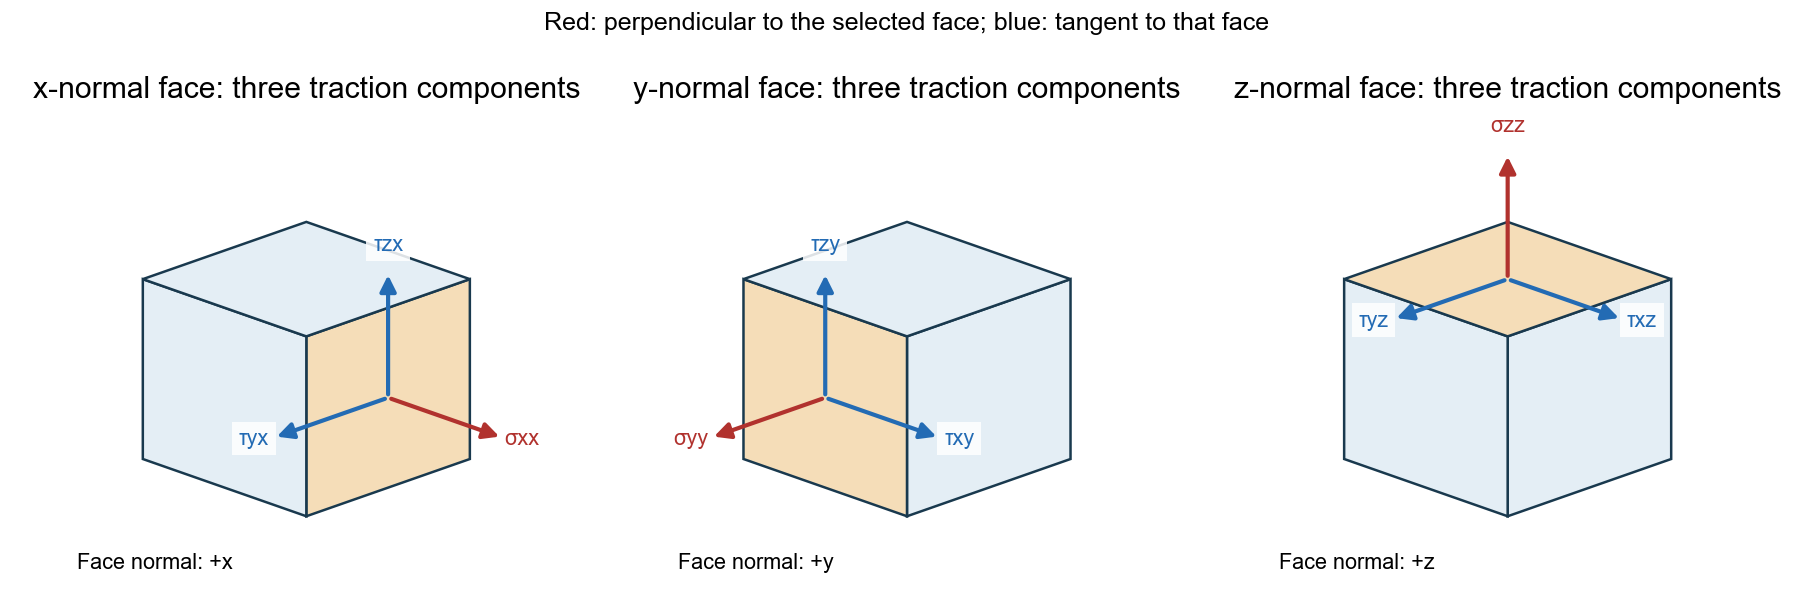

In [10]:
#@title Stress element — normal and tangential traction on x, y and z faces
fig,axes=plt.subplots(1,3,figsize=(15,5.5),layout='constrained')
proj=lambda p:np.array([p[0]-p[1],1.1*p[2]-.35*(p[0]+p[1])])
vectors=[proj([1,0,0]),proj([0,1,0]),proj([0,0,1])]
faces=[[[1,0,0],[1,1,0],[1,1,1],[1,0,1]],
       [[0,1,0],[1,1,0],[1,1,1],[0,1,1]],
       [[0,0,1],[1,0,1],[1,1,1],[0,1,1]]]
names=['x','y','z']
for j,ax in enumerate(axes):
    for k,face in enumerate(faces):
        ax.add_patch(Polygon([proj(p) for p in face],facecolor='#e4eef5' if k!=j else '#f5ddb8',edgecolor='#19394e',lw=1.5))
    origin=proj(np.mean(faces[j],axis=0))
    for i,vector in enumerate(vectors):
        target=origin+.70*vector
        arrow(ax,origin,target,'#b1322e' if i==j else '#236bb4')
        label=('σ' if i==j else 'τ')+names[i]+names[j]
        ax.text(*(target+.12*vector),label,color='#b1322e' if i==j else '#236bb4',ha='center',fontsize=13,
                bbox=dict(facecolor='white',edgecolor='none',alpha=.85))
    ax.text(-1.4,-1.02,f'Face normal: +{names[j]}',fontsize=13)
    ax.set(xlim=(-1.8,1.8),ylim=(-1.2,1.8),title=f'{names[j]}-normal face: three traction components')
    ax.set_aspect('equal');ax.axis('off')
fig.suptitle('Red: perpendicular to the selected face; blue: tangent to that face',fontsize=15)
plt.show()

### 4.2. Stress tensor — select a face, then select a force direction

We use σᵢⱼ = force/traction component in direction i on a face with normal in direction j. For example, σ_zx is the vertical shear on an x-normal beam cut, while σ_xz is longitudinal shear on a z-normal face. They act on different faces. In a classical continuum without couple stresses, moment balance gives σ_zx = σ_xz.

$$\boldsymbol{\sigma}=
\begin{bmatrix}
\sigma_{xx}&\tau_{xy}&\tau_{xz}\\
\tau_{yx}&\sigma_{yy}&\tau_{yz}\\
\tau_{zx}&\tau_{zy}&\sigma_{zz}
\end{bmatrix},
\qquad \mathbf t(\mathbf n)=\boldsymbol{\sigma}\mathbf n.$$

Diagonal entries are normal stresses. Off-diagonal entries are shear stresses. Three faces times three components makes nine entries; symmetry leaves six independent components. The cube drawing identifies each component. The beam model below retains the dominant longitudinal bending stress and transverse shear; it does not compute every component of a three-dimensional solid.

The cube arrows illustrate positive tensor components, not the numerical load case. Reversing a face normal reverses its traction vector. [MIT primary reading on stress and equilibrium](https://ocw.mit.edu/courses/2-080j-structural-mechanics-fall-2013/8e61abd2b094e2214465ce18ab8eb440_MIT2_080JF13_Lecture3.pdf).

### 4.3. First draw the cross-section — then calculate A and I

The next drawing fixes b, h, z, c and the neutral axis before area or stress calculations. Width b lies along y; height h lies along z. A thin horizontal strip has area dA = b dz.

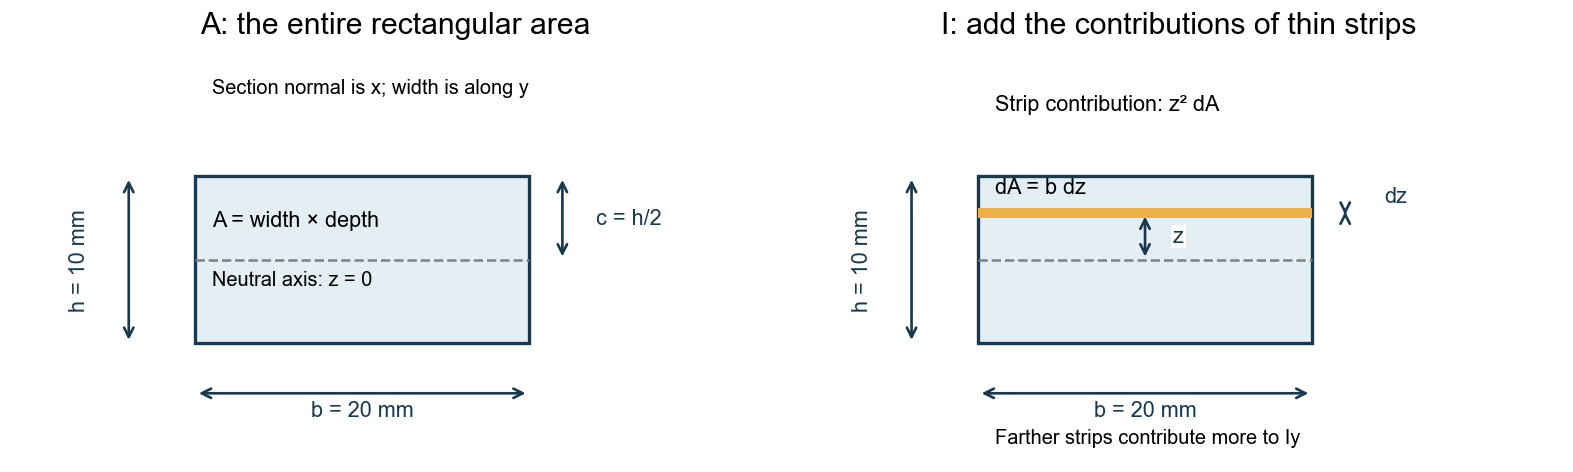

In [11]:
#@title Figure 4 — draw the area and dimensions before calculating A and I
fig,axes=plt.subplots(1,2,figsize=(13,5.5),layout='constrained')
for ax in axes:
    ax.add_patch(Rectangle((-b/2,-h/2),b,h,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
    ax.plot([-b/2,b/2],[0,0],'--',color='gray')
    dimension(ax,(-b/2,-8),(b/2,-8),'b = 20 mm',(0,-1))
    dimension(ax,(-14,-h/2),(-14,h/2),'h = 10 mm',(-3,0),rotation=90)
    ax.set(xlim=(-21,25),ylim=(-12,13));ax.set_aspect('equal');ax.axis('off')
axes[0].set_title('A: the entire rectangular area')
axes[0].text(-9,2,'A = width × depth',fontsize=13)
axes[0].text(-9,-1.5,'Neutral axis: z = 0',fontsize=12)
dimension(axes[0],(12,0),(12,h/2),'c = h/2',(4,0))
axes[0].text(-9,10,'Section normal is x; width is along y',fontsize=12)
axes[1].set_title('I: add the contributions of thin strips')
axes[1].add_patch(Rectangle((-b/2,2.5),b,.6,facecolor='#eeb147'))
dimension(axes[1],(0,0),(0,2.8),'z',(2,0))
axes[1].text(-9,4,'dA = b dz',fontsize=13)
dimension(axes[1],(12,2.5),(12,3.1),'dz',(3,1))
axes[1].text(-9,9,'Strip contribution: z² dA',fontsize=13)
axes[1].text(-9,-11,'Farther strips contribute more to Iy',fontsize=12)
plt.show()

$$A=bh=(20)(10)=200\ \mathrm{mm^2},$$

$$I_y=\int_A z^2\,dA=b\int_{-h/2}^{h/2}z^2\,dz
=\frac{bh^3}{12}=1666.6667\ \mathrm{mm^4},\qquad c=h/2=5\ \mathrm{mm}.$$

A counts area once. I weights it by distance squared from the neutral axis, so material farther away has more bending leverage. I is section geometry, not material stiffness or mass moment of inertia. E = 2000 MPa is our assumed material modulus; EI combines material and geometry.

### 4.4. Bending normal stress on this section

For the root section of Example A, M = −PL = −900 N mm. With sagging-positive M, upward-positive z and tension-positive stress:

$$\boxed{\sigma_{xx}(z)=-\frac{Mz}{I_y}},\qquad
|\sigma_{\max}|=\frac{|M|c}{I_y}=2.70\ \mathrm{MPa}.$$

At z = +5 mm the stress is +2.70 MPa (top tension); at z = 0 it is zero; at z = −5 mm it is −2.70 MPa (bottom compression). These are stresses **along x**, drawn on the cross-section normal to x. Section 5 derives this relation from fibre strain and material response.

The earlier shorthand σₓ means this component σₓₓ; εₓ likewise means longitudinal εₓₓ. A direction subscript is not an extra variable.

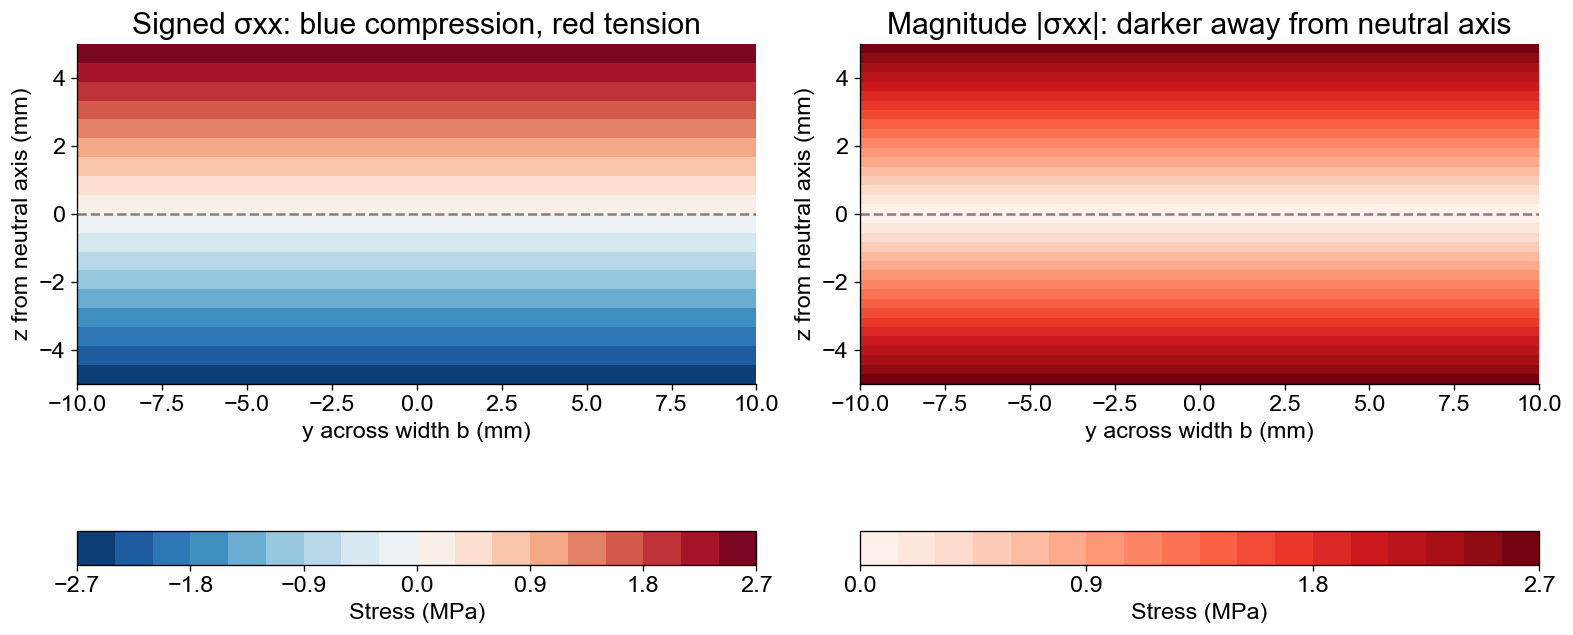

In [12]:
#@title Bending stress contour on the root cross-section — not a damage plot
yy,zz=np.meshgrid(np.linspace(-b/2,b/2,121),np.linspace(-h/2,h/2,121))
normal_field=P*L*zz/I
normal_peak=max(float(np.max(abs(normal_field))),1e-12)
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for ax,field,cmap,levels,title in [
 (axes[0],normal_field,'RdBu_r',np.linspace(-normal_peak,normal_peak,19),'Signed σxx: blue compression, red tension'),
 (axes[1],abs(normal_field),'Reds',np.linspace(0,normal_peak,19),'Magnitude |σxx|: darker away from neutral axis')]:
    image=ax.contourf(yy,zz,field,levels=levels,cmap=cmap)
    ax.axhline(0,color='gray',ls='--');ax.set(xlabel='y across width b (mm)',ylabel='z from neutral axis (mm)',title=title)
    ticks=np.linspace(-normal_peak,normal_peak,7) if ax is axes[0] else np.linspace(0,normal_peak,4)
    ax.set_aspect('equal');fig.colorbar(image,ax=ax,orientation='horizontal',pad=.22,label='Stress (MPa)',ticks=ticks)
plt.show()
assert np.isclose(normal_field[-1,0],P*L*h/(2*I)) and np.isclose(normal_field[0,0],-P*L*h/(2*I))

**Read the contour:** red means tension, blue means compression. Colour intensity increases with |z|, not monotonically with signed z across both halves. In the upper half, increasing z makes tension darker; moving downward below the neutral axis makes compression darker. The second panel shows magnitude only. Both plots are analytical fields on the solid rectangle, not a 3-D finite-element result or a damage image.

**Why not simply divide 2 N by A?** The 2 N applied force is transverse to the beam, so 2/200 = 0.010 MPa is an average transverse shear, not the longitudinal bending stress. Bending produces a tension/compression couple: integrating the root stress over the upper half gives 135 N tension, and the lower half gives 135 N compression. Their net axial force is zero but their combined moment is 900 N mm. Normal stress can therefore be large even though no net axial force is applied.

### 4.5. What Q means physically

Choose a horizontal cut at z = +2.5 mm and select only the material **above** it. Its first moment about the neutral axis is:

$$Q(z)=\int_{A^*}z'\,dA=A^*\bar z^*
=\frac b2\left[\left(\frac h2\right)^2-z^2\right].$$

Q is not a load and not merely area. Its mm³ units combine selected area and its centroid's bending lever arm. I describes the whole section with z² weighting; Q describes this selected region with z weighting.

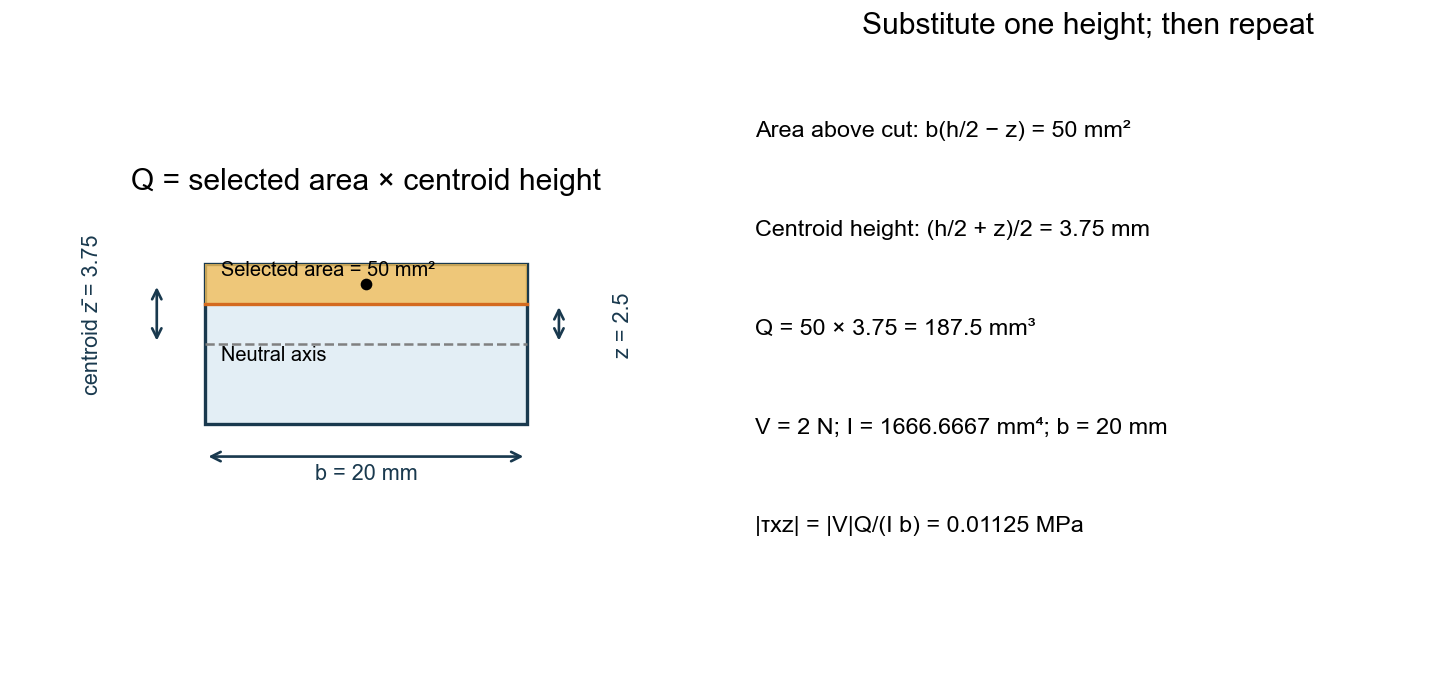

In [13]:
#@title Figure 4B — first moment Q uses the area above a chosen cut
fig,axes=plt.subplots(1,2,figsize=(12,5.5),layout='constrained')
ax=axes[0]; chosen_z=2.5
ax.add_patch(Rectangle((-10,-5),20,10,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
ax.add_patch(Rectangle((-10,chosen_z),20,5-chosen_z,facecolor='#f1be5a',alpha=.8))
ax.plot([-10,10],[chosen_z,chosen_z],color='#d46a1f',lw=2)
ax.plot([-10,10],[0,0],'--',color='gray')
ax.plot(0,3.75,'ko')
ax.text(-9,4.3,'Selected area = 50 mm²',fontsize=12)
ax.text(-9,-1,'Neutral axis',fontsize=12)
dimension(ax,(12,0),(12,chosen_z),'z = 2.5',(4,0),rotation=90)
dimension(ax,(-13,0),(-13,3.75),'centroid z̄ = 3.75',(-4,0),rotation=90)
dimension(ax,(-10,-7),(10,-7),'b = 20 mm',(0,-1))
ax.set(xlim=(-22,22),ylim=(-10,9),title='Q = selected area × centroid height')
ax.set_aspect('equal');ax.axis('off')
ax=axes[1];ax.axis('off')
lines=['Area above cut: b(h/2 − z) = 50 mm²',
       'Centroid height: (h/2 + z)/2 = 3.75 mm',
       'Q = 50 × 3.75 = 187.5 mm³',
       'V = 2 N; I = 1666.6667 mm⁴; b = 20 mm',
       '|τxz| = |V|Q/(I b) = 0.01125 MPa']
for j,line in enumerate(lines):
    ax.text(.03,.85-j*.16,line,transform=ax.transAxes,fontsize=14)
ax.set_title('Substitute one height; then repeat')
plt.show()

### Why that selected area requires shear transfer

The longitudinal bending-force resultant carried by the shaded upper material is:

$$N^*(x)=\int_{A^*}\sigma_{xx}\,dA=-\frac{M(x)Q}{I}.$$

Because bending moment changes along x, this force changes from one cut to a neighbouring cut. Shear across the lower boundary of the shaded material transfers the difference. The next diagram isolates that upper slice. Its longitudinal force balance is −Nₗ + Nᵣ + F_interface = 0. These longitudinal forces are not the 2 N vertical load.

Since dM/dx = V, the required shear-force transfer per unit span is |s| = |VQ|/I. Divide by the solid width b of the interface to obtain shear-stress magnitude:

$$\boxed{|\tau_{xz}|=\frac{|V|Q}{Ib}},\qquad \tau_{zx}=\tau_{xz}.$$

The second equality is complementary shear from stress symmetry. Thus the same magnitude appears as vertical shear on a beam cross-section and longitudinal shear on the horizontal interface.

**Face signs matter:** the isolated upper slice's lower interface has normal −z and receives force in +x. Consequently its positive-face tensor component σ_xz is negative. With the app's M′ = V convention, τxz = τzx = −VQ/(Ib). On the outboard portion's left face (normal −x), that negative component produces an upward traction. The following contour deliberately shows magnitude, not signed components.

[Roylance's beam-stress derivation](https://eng.libretexts.org/Bookshelves/Mechanical_Engineering/Mechanics_of_Materials_(Roylance)/04:_Bending/4.02:_Stresses_in_Beams) explains the selected-area force transfer; its coordinate/index conventions differ, so use the explicit convention of this notebook.

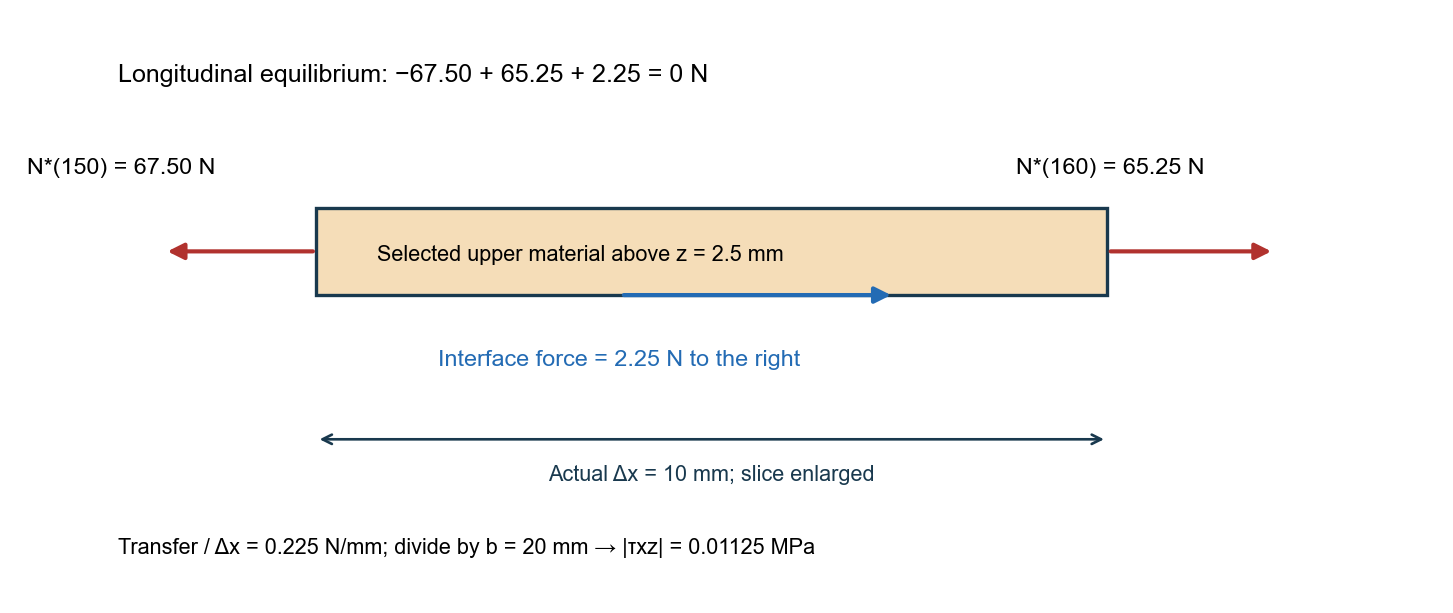

In [14]:
#@title Q determines the longitudinal-force difference that interface shear transfers
Qchosen=187.5;dx=10.;Mleft=-P*(L-150);Mright=-P*(L-160)
Nleft=-Mleft*Qchosen/I;Nright=-Mright*Qchosen/I
transfer=Nleft-Nright
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
ax.add_patch(Rectangle((100,0),260,20,facecolor='#f5ddb8',edgecolor='#19394e',lw=2))
arrow(ax,(100,10),(50,10),'#b1322e');ax.text(5,28,f'N*(150) = {Nleft:.2f} N',fontsize=14)
arrow(ax,(360,10),(415,10),'#b1322e');ax.text(330,28,f'N*(160) = {Nright:.2f} N',fontsize=14)
arrow(ax,(200,0),(290,0),'#236bb4');ax.text(140,-16,f'Interface force = {transfer:.2f} N to the right',fontsize=14,color='#236bb4')
dimension(ax,(100,-33),(360,-33),'Actual Δx = 10 mm; slice enlarged',(0,-8))
ax.text(120,8,'Selected upper material above z = 2.5 mm',fontsize=13)
ax.text(35,49,'Longitudinal equilibrium: −67.50 + 65.25 + 2.25 = 0 N',fontsize=15)
ax.text(35,-59,'Transfer / Δx = 0.225 N/mm; divide by b = 20 mm → |τxz| = 0.01125 MPa',fontsize=13)
ax.set(xlim=(0,470),ylim=(-70,65));ax.axis('off')
plt.show()
assert np.isclose(transfer,2.25)

For the solid rectangle, substitute Q(z) and I = bh³/12:

$$|\tau_{zx}(z)|=\frac{3|V|}{2bh}
\left[1-\left(\frac{2z}{h}\right)^2\right].$$

At V = 2 N, the maximum is 0.015 MPa at z = 0, and the top/bottom surfaces have zero shear. At z = 2.5 mm, Q = 187.5 mm³ and shear is 0.01125 MPa. The normal-stress maximum and shear-stress maximum occur at different heights.

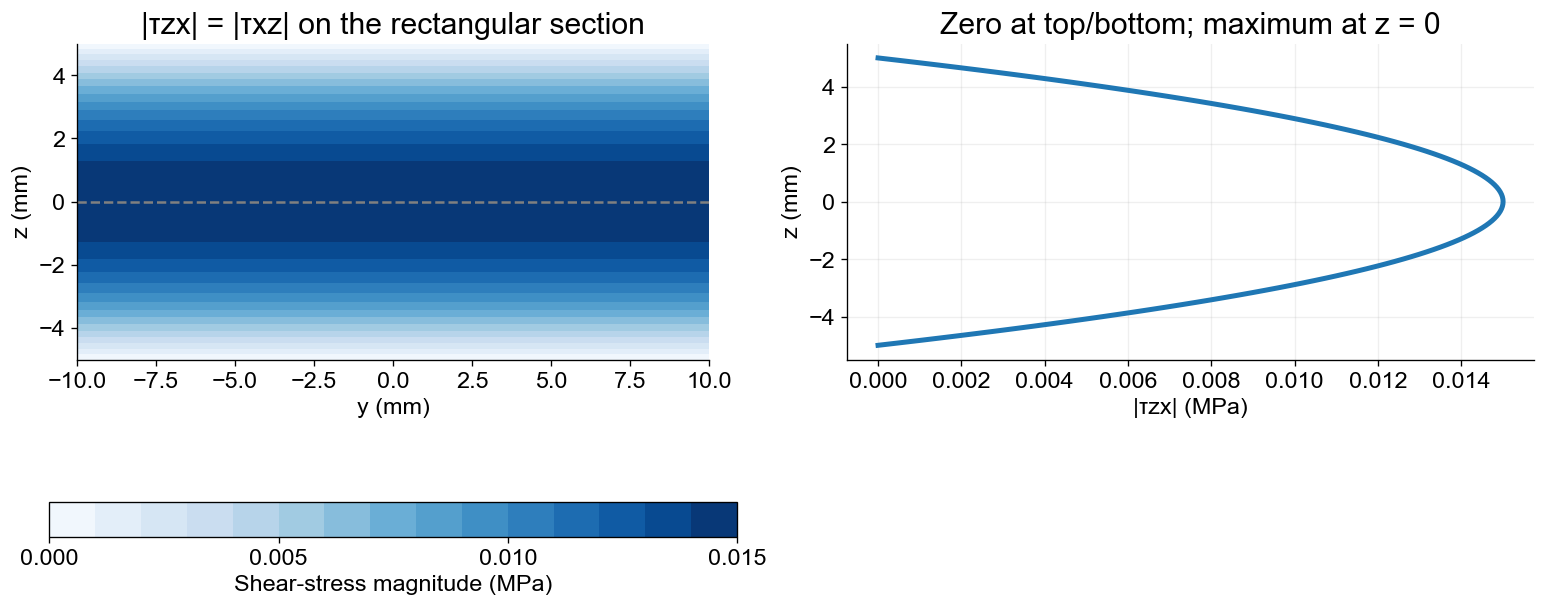

In [15]:
#@title Rectangular transverse shear magnitude — darkest at neutral axis
shear_field=1.5*abs(P)/A*(1-(2*zz/h)**2)
shear_peak=max(float(np.max(shear_field)),1e-12)
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
image=axes[0].contourf(yy,zz,shear_field,levels=np.linspace(0,shear_peak,16),cmap='Blues')
axes[0].axhline(0,color='gray',ls='--');axes[0].set(xlabel='y (mm)',ylabel='z (mm)',title='|τzx| = |τxz| on the rectangular section');axes[0].set_aspect('equal')
fig.colorbar(image,ax=axes[0],orientation='horizontal',pad=.22,label='Shear-stress magnitude (MPa)',ticks=np.linspace(0,shear_peak,4))
axes[1].plot(shear_field[:,0],zz[:,0],lw=3);axes[1].set(xlabel='|τzx| (MPa)',ylabel='z (mm)',title='Zero at top/bottom; maximum at z = 0');axes[1].grid(alpha=.2)
plt.show()
assert np.isclose(shear_field[0,0],0) and np.isclose(shear_field[60,0],1.5*abs(P)/A)

### One section, two different stress distributions

| z (mm) | σₓₓ (MPa) | Shear magnitude (MPa) |
|---:|---:|---:|
| +5 | +2.700 | 0 |
| +2.5 | +1.350 | 0.01125 |
| 0 | 0 | 0.01500 |
| −2.5 | −1.350 | 0.01125 |
| −5 | −2.700 | 0 |

The contour colours and profiles follow these values. Do not add maximum bending stress and maximum shear as if they occupied the same point. A real wing box uses thin-wall shear flow and its own geometry; the solid-rectangle formula is not obtained by substituting wing-skin thickness for b. Nominal beam stresses also exclude clamp-edge concentrations, holes and buckling.

## 5. Learn strain before the bending-strain equation

### 5.1. Normal strain, shear strain and the strain tensor

Strain measures **local change of shape or length**, not rigid translation. Normal strain is the relative change in a material line's length:

$$\varepsilon_{xx}=\frac{\Delta\ell_x}{\ell_x}.$$

Extension is positive; shortening is negative. Normal strains εₓₓ, εᵧᵧ and εzz refer to lines initially along x, y and z. Shear strain describes the change of the right angle between material lines. Engineering shear γxz is the total small change in that angle; the tensor component is half of it.

For displacement vector u = (uₓ,uᵧ,u_z), the small-strain tensor is:

$$\varepsilon_{ij}=\frac12\left(\frac{\partial u_i}{\partial x_j}
+\frac{\partial u_j}{\partial x_i}\right),$$

$$\boldsymbol{\varepsilon}=
\begin{bmatrix}
\varepsilon_{xx}&\gamma_{xy}/2&\gamma_{xz}/2\\
\gamma_{xy}/2&\varepsilon_{yy}&\gamma_{yz}/2\\
\gamma_{xz}/2&\gamma_{yz}/2&\varepsilon_{zz}
\end{bmatrix}.$$

The tensor is symmetric. Normal strains are fractional length changes; shear entries measure distortion. Strain is dimensionless (small angles are conventionally expressed in radians). Do not confuse stress τxz, measured in MPa, with shear strain γxz. A rigid translation or infinitesimal rigid rotation produces no small strain.

[MIT primary reading on the concept of strain](https://ocw.mit.edu/courses/2-080j-structural-mechanics-fall-2013/71034688fba0ff26d25653a4bd236a4a_MIT2_080JF13_Lecture2.pdf). The notebook uses the small-strain symmetric displacement gradient; finite rotations require a different strain measure.

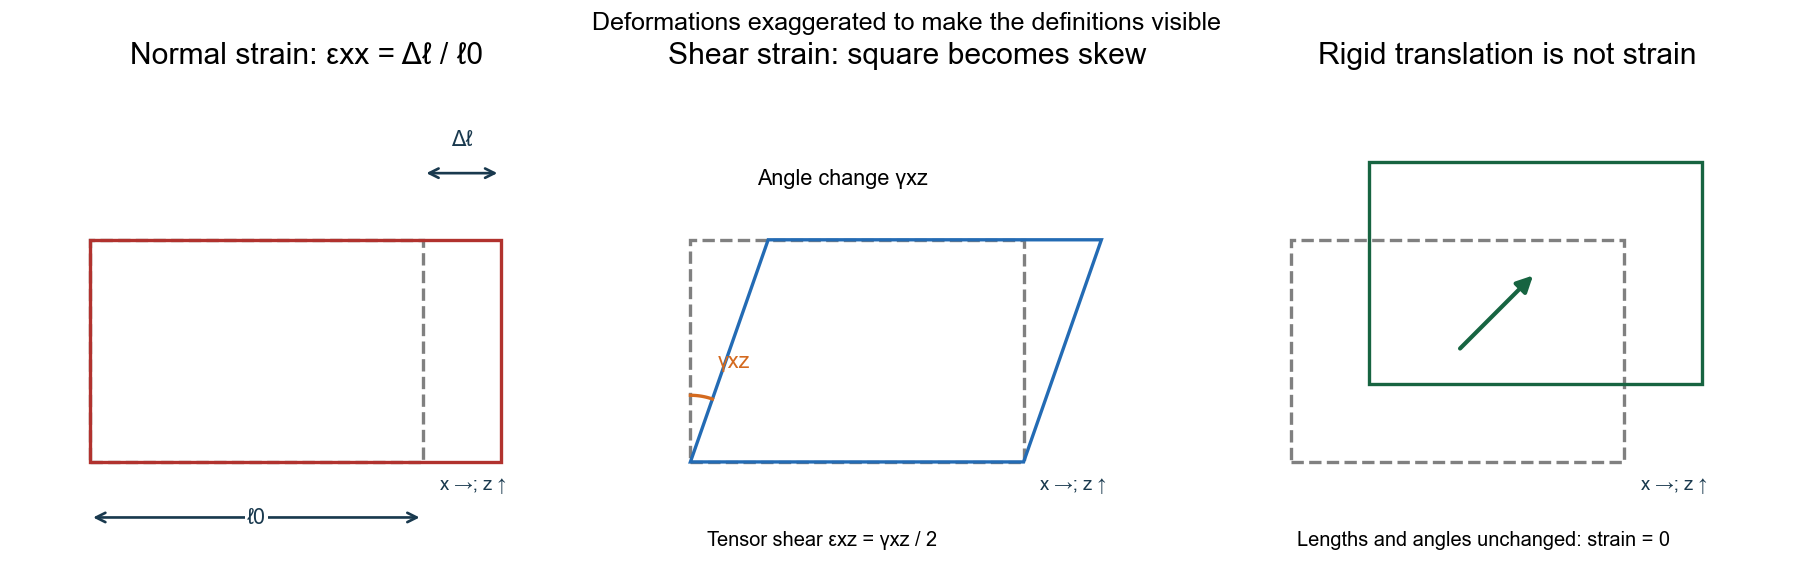

In [16]:
#@title Material-line changes — stretch, shear distortion and rigid translation
fig,axes=plt.subplots(1,3,figsize=(15,5),layout='constrained')
for ax in axes:
    ax.add_patch(Rectangle((0,0),3,2,fill=False,edgecolor='gray',ls='--',lw=2))
    ax.set(xlim=(-.7,4.6),ylim=(-1,3.5));ax.set_aspect('equal');ax.axis('off')
axes[0].add_patch(Rectangle((0,0),3.7,2,fill=False,edgecolor='#b1322e',lw=2))
dimension(axes[0],(0,-.5),(3,-.5),'ℓ0')
dimension(axes[0],(3,2.6),(3.7,2.6),'Δℓ',(0,.3))
axes[0].set_title('Normal strain: εxx = Δℓ / ℓ0')
axes[1].add_patch(Polygon([[0,0],[3,0],[3.7,2],[.7,2]],fill=False,edgecolor='#236bb4',lw=2))
angles=np.linspace(np.arctan2(2,.7),np.pi/2,50)
axes[1].plot(.6*np.cos(angles),.6*np.sin(angles),color='#d46a1f',lw=2)
axes[1].text(.25,.85,'γxz',fontsize=13,color='#d46a1f')
axes[1].text(.6,2.5,'Angle change γxz',fontsize=13)
axes[1].text(.15,-.75,'Tensor shear εxz = γxz / 2',fontsize=12)
axes[1].set_title('Shear strain: square becomes skew')
axes[2].add_patch(Rectangle((.7,.7),3,2,fill=False,edgecolor='#176441',lw=2))
arrow(axes[2],(1.5,1),(2.2,1.7),'#176441')
axes[2].text(.05,-.75,'Lengths and angles unchanged: strain = 0',fontsize=12)
axes[2].set_title('Rigid translation is not strain')
fig.suptitle('Deformations exaggerated to make the definitions visible',fontsize=15)
for ax in axes:
    ax.text(3.15,-.25,'x →; z ↑',fontsize=11,color='#19394e')
plt.show()

### 5.2. Apply the strain definition to bending fibres

### Start with the definition of strain

Longitudinal strain εₓ is the change in a material fibre's length divided by its original length. It is dimensionless. A strain of 0.00135 means a 0.135% change in length, not a 0.00135 mm displacement:

$$\varepsilon_x=\frac{\ell-\ell_0}{\ell_0}=\frac{\Delta\ell}{\ell_0}.$$

In the elementary bending model, cross-sections remain plane and perpendicular to the neutral fibre. Adjacent sections rotate relative to each other. With no net axial extension, the neutral fibre keeps its length; fibres farther from it lengthen or shorten more.

### Read the arc geometry in the next figure

The neutral fibre follows a small arc of radius R and angle Δφ. Its length is RΔφ. For the downward-curving case drawn, the top fibre at positive z is farther from the centre of curvature and has length (R + z)Δφ. Subtracting the neutral-fibre length gives:

$$\varepsilon_x=\frac{(R+z)\Delta\phi-R\Delta\phi}{R\Delta\phi}
=\frac{z}{R}=z\kappa.$$

Here R is a curvature radius, **not a support reaction**. The bottom fibre has negative z and therefore negative strain. This sign statement is tied to our drawn positive, downward curvature; reversing the load reverses the curvature and the tension/compression sides.

### Connect the geometry to the beam's displacement

With v positive downward, the exact signed curvature of the centreline graph is:

$$\kappa=\frac{v''}{[1+(v')^2]^{3/2}}\approx v''\qquad\text{for small slopes}.$$

Linear elastic material obeys Hooke's law σₓ = E εₓ. The signed sagging-positive moment is the moment of the longitudinal stress distribution:

$$M=-\int_A z\sigma_x\,dA=-E\kappa\int_A z^2\,dA=-EI\kappa.$$

The minus sign belongs to the chosen sagging-positive M and downward-positive v conventions. This chain gives both relations rather than introducing them as unrelated formulas:

$$\boxed{\varepsilon_x=zv''},\qquad
\boxed{\sigma_x=E\varepsilon_x=-\frac{Mz}{I}},\qquad
\boxed{v''=-\frac{M}{EI}}.$$

At the root of Example A, κ = 900/3,333,333.33 = 0.000270 mm⁻¹. At z = +5 mm, εₓ = 0.001350 and σₓ = 2000 × 0.001350 = 2.700 MPa. That is the top point of Figure 4. The curvature relation is an approximation to beam geometry, not a new applied load.

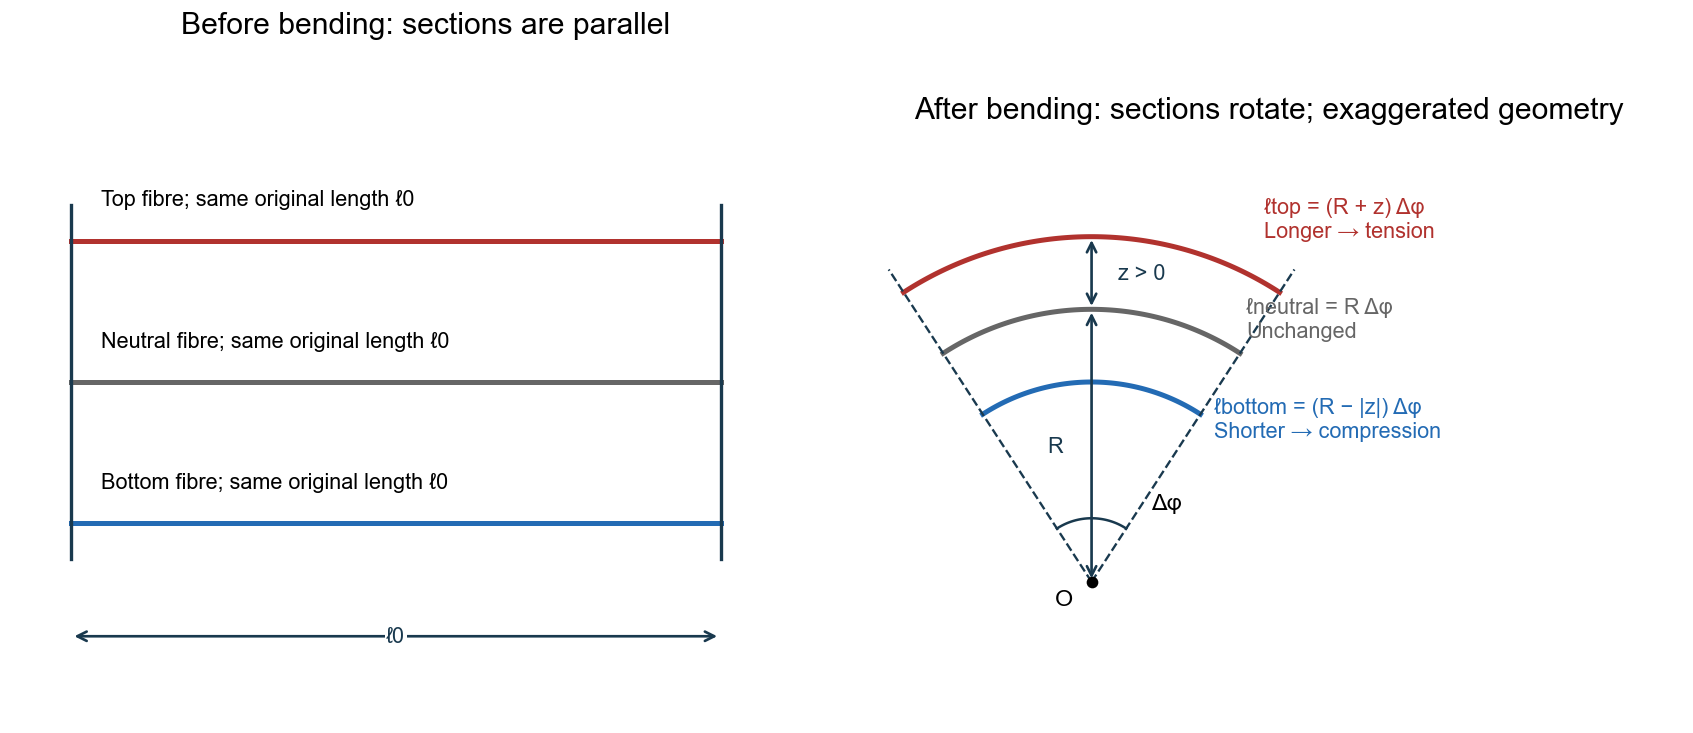

In [17]:
#@title Figure 5A — equal original fibres become different-length arcs
fig,axes=plt.subplots(1,2,figsize=(14,6),layout='constrained')
ax=axes[0]
for zz,col,name in [(20,'#b1322e','Top fibre'),(0,'#666666','Neutral fibre'),(-20,'#236bb4','Bottom fibre')]:
    ax.plot([0,110],[zz,zz],color=col,lw=3)
    ax.text(5,zz+5,name+'; same original length ℓ0',fontsize=13)
for xx in [0,110]: ax.plot([xx,xx],[-25,25],color='#19394e',lw=2)
dimension(ax,(0,-36),(110,-36),'ℓ0')
ax.set(xlim=(-10,130),ylim=(-48,48),title='Before bending: sections are parallel')
ax.axis('off')
ax=axes[1]
Rdemo=60.; zdemo=16.
ang=np.linspace(np.deg2rad(57),np.deg2rad(123),100)
for rad,col,label in [(Rdemo+zdemo,'#b1322e','Top: (R + z) Δφ'),(Rdemo,'#666666','Neutral: R Δφ'),(Rdemo-zdemo,'#236bb4','Bottom: (R − |z|) Δφ')]:
    ax.plot(rad*np.cos(ang),rad*np.sin(ang),color=col,lw=3)
for a in [ang[0],ang[-1]]:
    ax.plot([0,82*np.cos(a)],[0,82*np.sin(a)],color='#19394e',lw=1.4,ls='--')
ax.plot(0,0,'ko'); ax.text(-8,-5,'O',fontsize=14)
dimension(ax,(0,0),(0,Rdemo),'R',(-8,0))
dimension(ax,(0,Rdemo),(0,Rdemo+zdemo),'z > 0',(11,0))
ax.plot(14*np.cos(ang),14*np.sin(ang),color='#19394e')
ax.text(13,16,'Δφ',fontsize=14)
ax.text(38,76,'ℓtop = (R + z) Δφ\nLonger → tension',fontsize=13,color='#b1322e')
ax.text(34,54,'ℓneutral = R Δφ\nUnchanged',fontsize=13,color='#666666')
ax.text(27,32,'ℓbottom = (R − |z|) Δφ\nShorter → compression',fontsize=13,color='#236bb4')
ax.set(xlim=(-52,130),ylim=(-12,100),title='After bending: sections rotate; exaggerated geometry')
ax.set_aspect('equal'); ax.axis('off')
plt.show()

For our beam coordinates, vertical material displacement u_z = −v because z points upward and v is defined downward. Plane sections remaining perpendicular to the neutral fibre give u_x = z v′. Therefore εₓₓ = ∂u_x/∂x = z v″. This fixes the sign of the bending strain. The **Euler–Bernoulli model neglects shear deformation**, although transverse shear stress still exists.

$$\gamma_{xz}=\frac{\partial u_x}{\partial z}+
\frac{\partial u_z}{\partial x}=v'-v'=0.$$

This zero is a kinematic approximation, not a claim that V or shear stress vanishes. Short/deep beams may need a shear-deformable model.

In this reduced theory, transverse shear stress is recovered from equilibrium while shear deformation is neglected. It is not an exact three-dimensional strain field. The relation σₓₓ = E εₓₓ is the beam's dominant uniaxial longitudinal response, not the general constitutive equation for a state with all nine stress components.

### Integrate curvature using the physical root constraints

For Example A the cut already gave M(x) = −P(L − x). Divide by EI to obtain curvature. Integrate along x to obtain rotation, then displacement:

$$v''=\frac{P(L-x)}{EI},$$

$$\theta=v'=\frac{P}{EI}\left(Lx-\frac{x^2}{2}\right)+C_1,$$

$$v=\frac{P}{EI}\left(\frac{Lx^2}{2}-\frac{x^3}{6}\right)+C_1x+C_2.$$

The fixed root gives θ(0) = 0, so C₁ = 0; it also gives v(0) = 0, so C₂ = 0. These constraints, labelled on Figure 5B, produce:

$$\theta(x)=\frac{Px(2L-x)}{2EI},\qquad
v(x)=\frac{Px^2(3L-x)}{6EI}.$$

At the tip, substitute x = L:

$$\boxed{v(L)=\frac{PL^3}{3EI}
=\frac{2(450)^3}{3(2000)(1666.6667)}
=18.225\ \mathrm{mm}}.$$

| Station | Curvature κ | Rotation θ | Displacement v |
|---|---:|---:|---:|
| Root x = 0 | 0.000270 mm⁻¹ | 0 rad | 0 mm |
| Cut x = 150 mm | 0.000180 mm⁻¹ | 0.033750 rad | 2.700 mm |
| Tip x = 450 mm | 0 mm⁻¹ | 0.060750 rad | 18.225 mm |

The root can have nonzero curvature and strain despite zero displacement and slope. At the tip, zero moment/curvature does not imply zero accumulated rotation or displacement. Integration carries the bending effect of the whole inboard span into the tip motion. The tip slope is about 3.48°, and deflection is about 4.05% of span; check the small-deflection approximation for a real test. This solid strip is not the actual airfoil-section wing.

Tip deflection = 18.2250 mm; root deflection = 0.0000 mm
Tip slope = 0.06075 rad


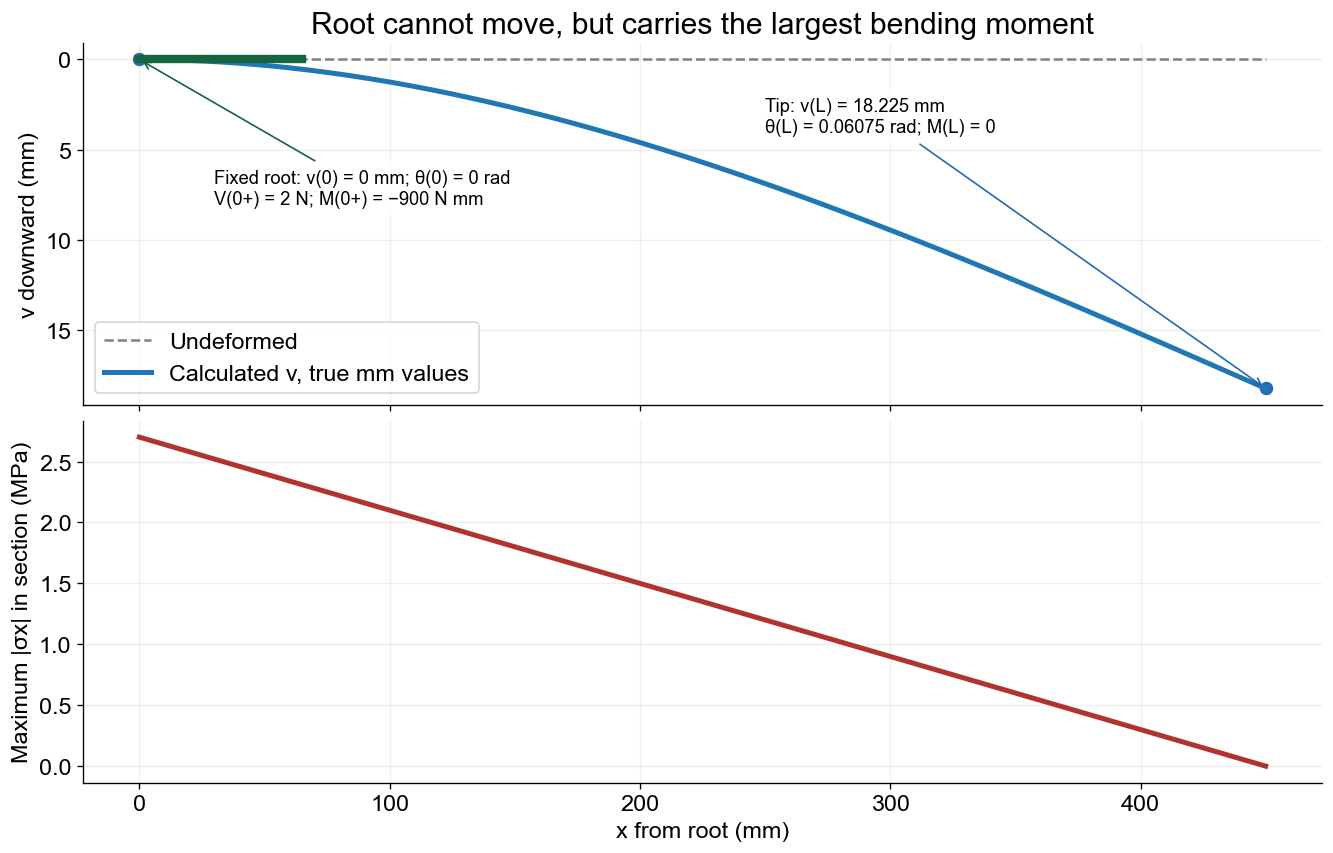

In [18]:
#@title Figure 5B — undeformed and deflected shape; stress is not displacement
v=P*x**2*(3*L-x)/(6*EI)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained',sharex=True)
axes[0].plot(x,np.zeros_like(x),'--',color='gray',label='Undeformed')
axes[0].plot(x,v,lw=3,label='Calculated v, true mm values')
axes[0].scatter([0,L],[0,v[-1]],color='#236bb4',s=50)
axes[0].plot([0,65],[0,0],color='#176441',lw=5)
axes[0].annotate('Fixed root: v(0) = 0 mm; θ(0) = 0 rad\nV(0+) = 2 N; M(0+) = −900 N mm',
                 xy=(0,0),xytext=(30,8),fontsize=11,
                 bbox=dict(facecolor='white',edgecolor='none',alpha=.9),
                 arrowprops=dict(arrowstyle='->',color='#176441'))
axes[0].annotate('Tip: v(L) = 18.225 mm\nθ(L) = 0.06075 rad; M(L) = 0',
                 xy=(L,v[-1]),xytext=(250,4),fontsize=11,
                 bbox=dict(facecolor='white',edgecolor='none',alpha=.9),
                 arrowprops=dict(arrowstyle='->',color='#236bb4'))
axes[0].invert_yaxis(); axes[0].set_ylabel('v downward (mm)'); axes[0].legend()
axes[0].set_title('Root cannot move, but carries the largest bending moment')
axes[1].plot(x,np.abs(M)*h/2/I,lw=3,color='#b1322e')
axes[1].set(xlabel='x from root (mm)',ylabel='Maximum |σx| in section (MPa)')
for ax in axes: ax.grid(alpha=.2)
plt.show()
print(f'Tip deflection = {v[-1]:.4f} mm; root deflection = {v[0]:.4f} mm')
print(f'Tip slope = {P*L**2/(2*EI):.5f} rad')

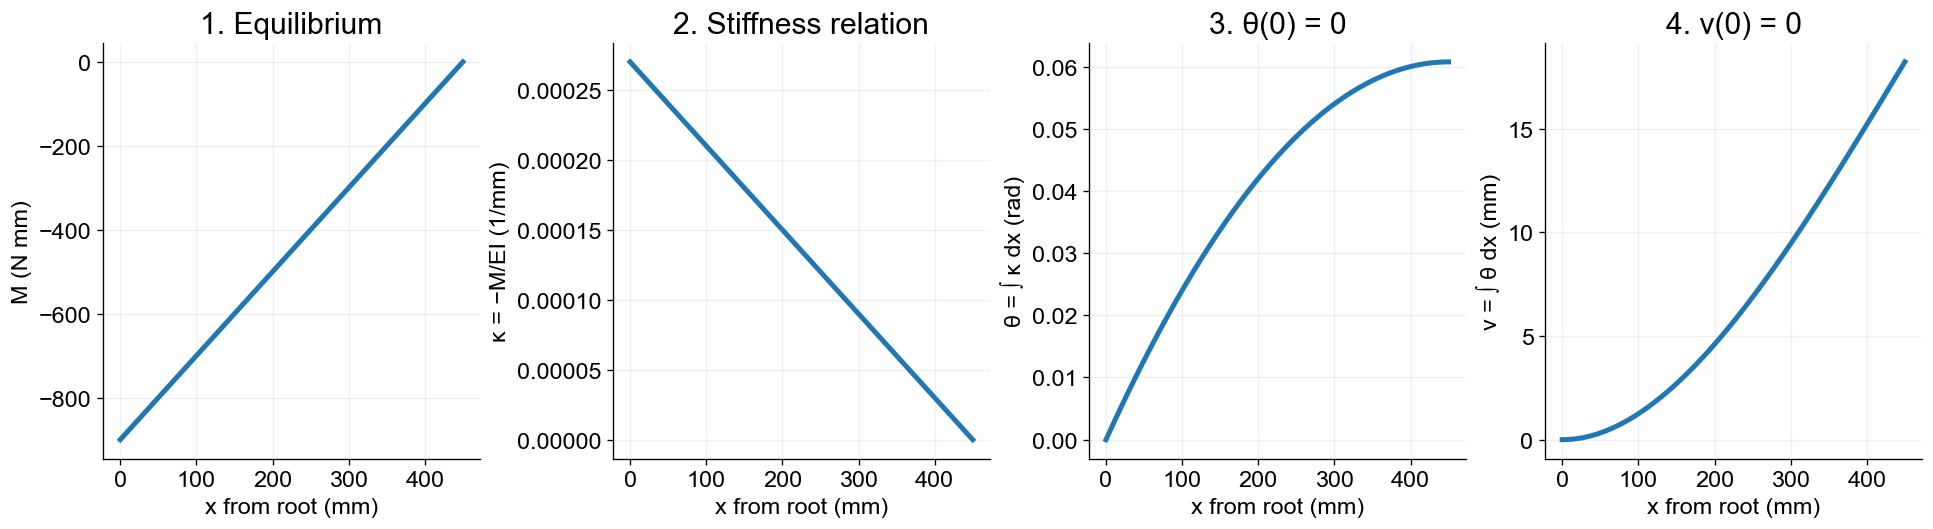

In [19]:
#@title Figure 5C — four stages of the calculation, with units
fig,axes=plt.subplots(1,4,figsize=(16,4.3),layout='constrained')
curvature=P*(L-x)/EI
theta=P*x*(2*L-x)/(2*EI)
for ax,yy,label in zip(axes,[M,curvature,theta,v],
 ['M (N mm)','κ = −M/EI (1/mm)','θ = ∫ κ dx (rad)','v = ∫ θ dx (mm)']):
    ax.plot(x,yy,lw=3)
    ax.set(xlabel='x from root (mm)',ylabel=label)
    ax.grid(alpha=.2)
axes[0].set_title('1. Equilibrium')
axes[1].set_title('2. Stiffness relation')
axes[2].set_title('3. θ(0) = 0')
axes[3].set_title('4. v(0) = 0')
plt.show()
assert abs(curvature[0]-.00027)<1e-12
assert abs(theta[-1]-.06075)<1e-12

### 5.3. Return to the support examples after learning displacement

All centre-force comparisons below use the same length, section, modulus and 2 N force. The maximum cantilever displacement is at its free tip, **not at the load station**.

| Case | Largest nominal bending stress | Maximum downward displacement |
|---|---:|---:|
| Cantilever, centre force | 1.350 MPa at root | 5.695313 mm at free tip; load station: 2.278125 mm |
| Pin–roller, centre force | 0.675 MPa at centre | 1.139063 mm at centre |
| Fixed–fixed, centre force | 0.3375 MPa at ends and centre | 0.284766 mm at centre |
| Cantilever tip extension (Example A) | 2.700 MPa at root | 18.225 mm at tip |
| Cantilever uniform extension (Example B) | 1.350 MPa at root | 6.834375 mm at tip |

For the simply supported centre force, integrating curvature with zero end displacement gives PL³/(48EI). For fixed–fixed it gives PL³/(192EI). The reactions were derived in their own support subsections, not inferred from these displacement formulas.

For Example B, M(x) = −q(L − x)²/2. Two integrations with v(0) = θ(0) = 0 give:

$$v(x)=\frac{qx^2}{24EI}(6L^2-4Lx+x^2),\qquad
v(L)=\frac{qL^4}{8EI}=6.834375\ \mathrm{mm}.$$

Its root moment matches the centre point-load cantilever, but displacement does not: whole-beam equivalent loads need not have the same internal strain field.

Uniform: root |M|=450.000 N mm; stress=1.350 MPa; tip v=6.834375 mm


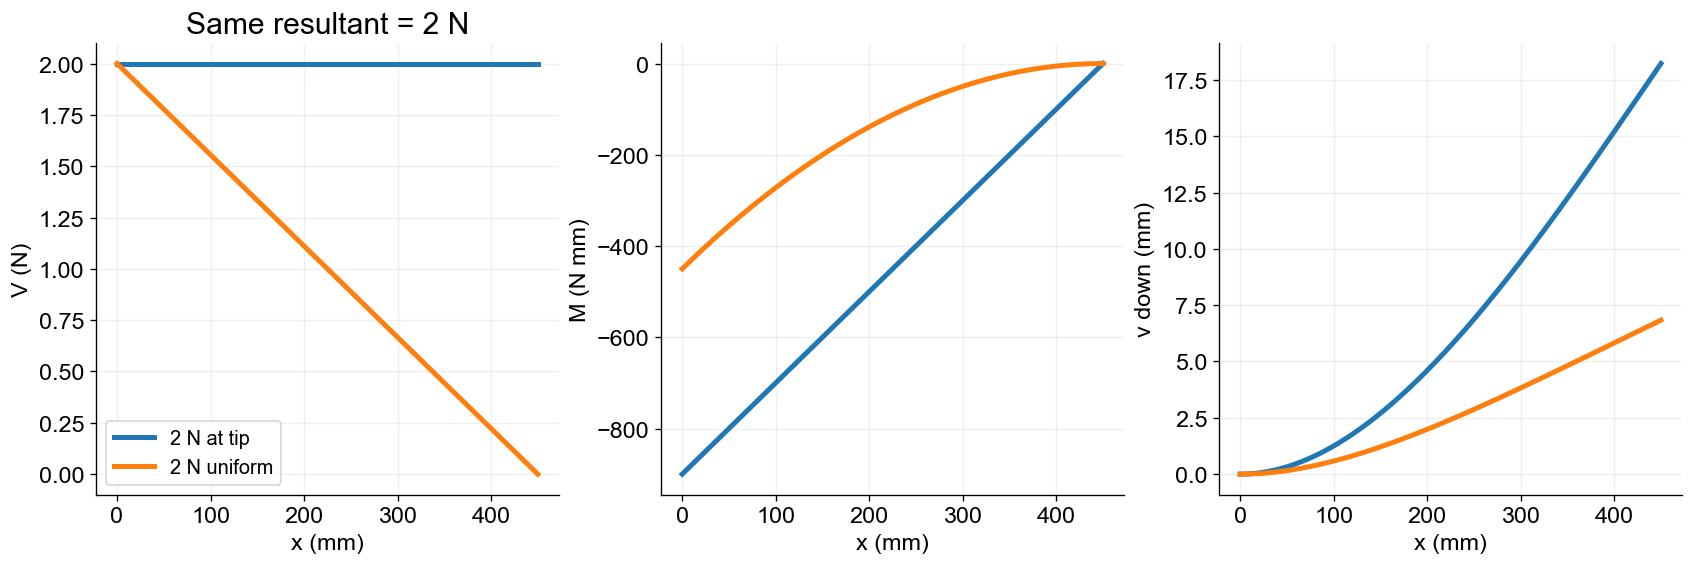

In [20]:
#@title Figure 6B — equal total load, different internal diagrams and displacement
q=P/L
Vu=q*(L-x); Mu=-q*(L-x)**2/2
vu=q*x**2*(6*L**2-4*L*x+x*x)/(24*EI)
fig,axes=plt.subplots(1,3,figsize=(14,4.6),layout='constrained')
for ax,y1,y2,label in zip(axes,[V,M,v],[Vu,Mu,vu],['V (N)','M (N mm)','v down (mm)']):
    ax.plot(x,y1,lw=3,label='2 N at tip'); ax.plot(x,y2,lw=3,label='2 N uniform')
    ax.set(xlabel='x (mm)',ylabel=label); ax.grid(alpha=.2)
axes[0].legend(fontsize=12); axes[0].set_title('Same resultant = 2 N')
plt.show()
print(f'Uniform: root |M|={q*L**2/2:.3f} N mm; stress={q*L**2*h/(4*I):.3f} MPa; tip v={vu[-1]:.6f} mm')

Pin–roller: max |M|=225.0000 N mm; max |σ|=0.675000 MPa; max v=1.139063 mm
Fixed–fixed: max |M|=112.5000 N mm; max |σ|=0.337500 MPa; max v=0.284766 mm


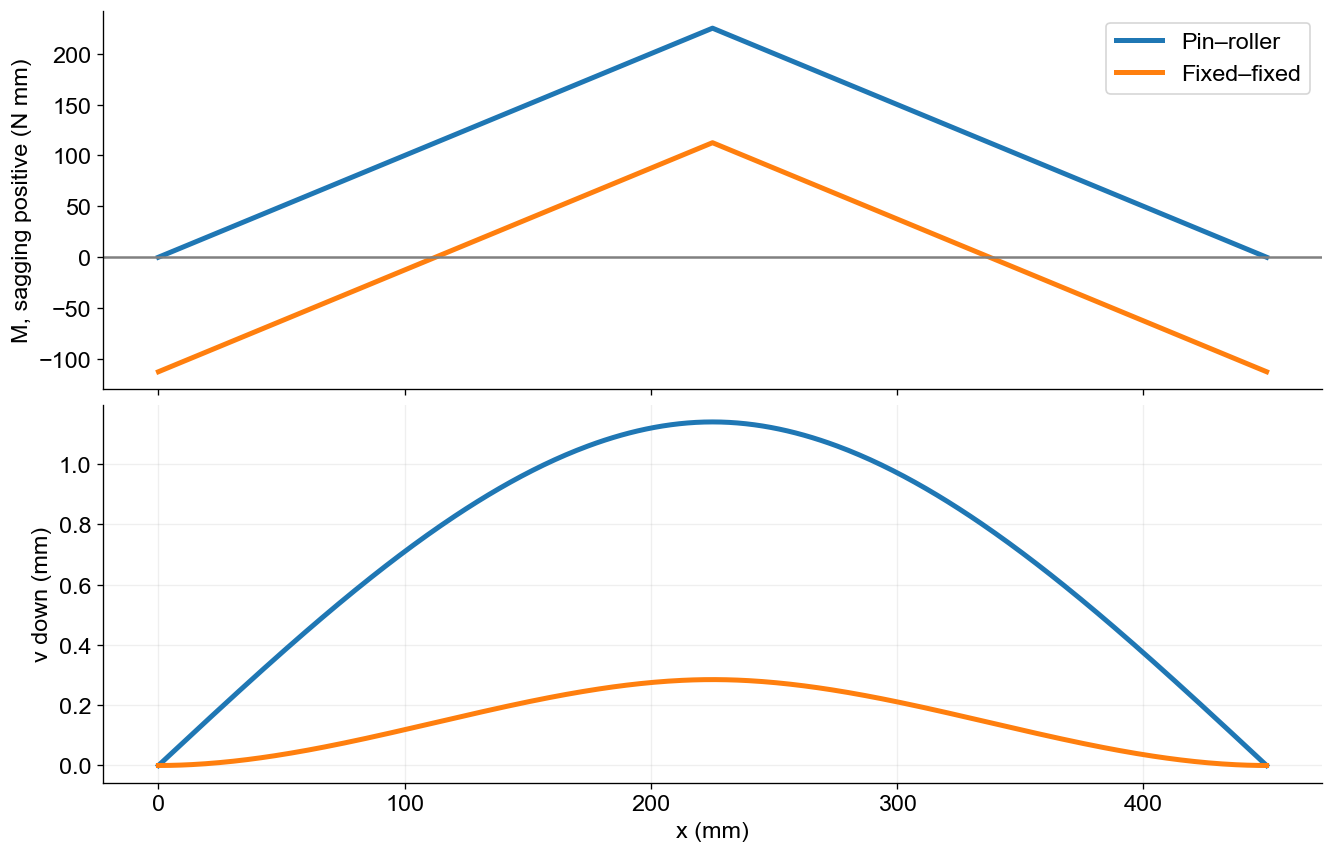

In [21]:
#@title Figure 7B — simply supported versus fixed–fixed, same centre force
Ms=np.where(x<=L/2,P*x/2,P*(L-x)/2)
Mf=Ms-P*L/8
xx=np.minimum(x,L-x)
vs=P*xx*(3*L**2-4*xx**2)/(48*EI)
vf=P*xx**2*(3*L-4*xx)/(48*EI)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained',sharex=True)
axes[0].plot(x,Ms,lw=3,label='Pin–roller'); axes[0].plot(x,Mf,lw=3,label='Fixed–fixed')
axes[0].axhline(0,color='gray'); axes[0].set_ylabel('M, sagging positive (N mm)'); axes[0].legend()
axes[1].plot(x,vs,lw=3,label='Pin–roller'); axes[1].plot(x,vf,lw=3,label='Fixed–fixed')
axes[1].set(xlabel='x (mm)',ylabel='v down (mm)'); axes[1].grid(alpha=.2)
plt.show()
for name,mm,vv in [('Pin–roller',Ms,vs),('Fixed–fixed',Mf,vf)]:
    print(f'{name}: max |M|={max(abs(mm)):.4f} N mm; max |σ|={max(abs(mm))*h/(2*I):.6f} MPa; max v={max(vv):.6f} mm')

### What the app actually solves

The app divides the beam into finite elements. Each node has a displacement and rotation. Element stiffness and consistent loads assemble into:

$$\mathbf K\mathbf u=\mathbf f.$$

Boundary conditions restrict selected components of  u. After solving the free components, the original equations recover reactions. The app reconstructs shear and moment from equilibrium and evaluates stress. Refining the mesh checks numerical sensitivity; it does not verify a real clamp, printed anisotropy or material strength. You do not need to derive element matrices today.

**Software activity A:** open the tip-load link. Find −2 N, −900 N mm, 2.70 MPa and 18.225 mm. Use the probe at 150 mm and check (M=-600) N mm. Explain any sign differences before declaring an error. Download the study record.

**Interpret each output separately:** reactions check whole-beam equilibrium; V and M describe each cut; stresses describe fibres within a selected section; v describes motion along the span. A colour map of stress is not a photograph of damage. A deflection animation is usually magnified; compare the numerical mm values.

Every example link below replaces the previous study with its prescribed load and support. First compare units and sign conventions, then numerical values. Return to the notebook and record one equilibrium check and one stress/deflection calculation. Mesh convergence checks discretization, not the material model.

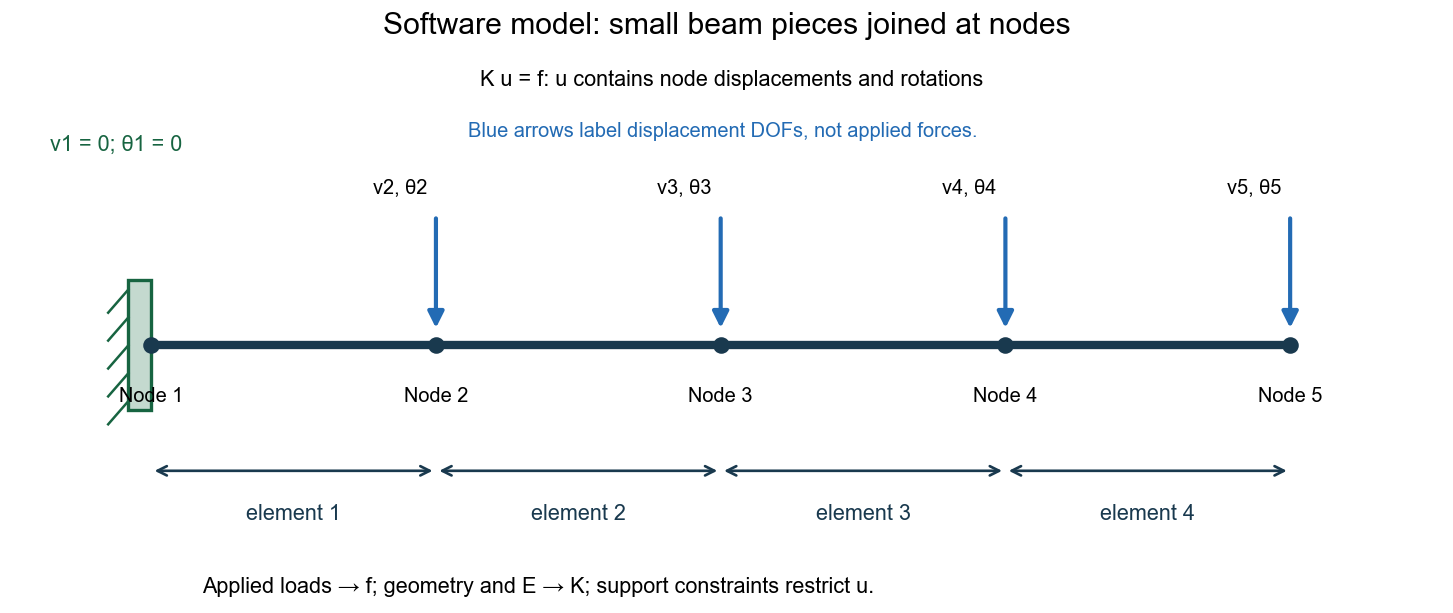

In [22]:
#@title Figure 5D — finite-element nodes carry displacement and rotation
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
clean_beam(ax,'Software model: small beam pieces joined at nodes')
support(ax,0,'fixed')
nodes=np.linspace(0,L,5)
ax.scatter(nodes,np.zeros_like(nodes),s=80,color='#19394e',zorder=5)
for j,xx in enumerate(nodes):
    ax.text(xx,-12,f'Node {j+1}',ha='center',fontsize=12)
    if j:
        arrow(ax,(xx,28),(xx,3),'#236bb4')
        ax.text(xx-25,33,f'v{j+1}, θ{j+1}',fontsize=12)
    if j<4:
        dimension(ax,(xx,-27),(nodes[j+1],-27),f'element {j+1}',(0,-9))
ax.text(-40,42,'v1 = 0; θ1 = 0',color='#176441',fontsize=13)
ax.text(130,56,'K u = f: u contains node displacements and rotations',fontsize=13)
ax.text(20,-53,'Applied loads → f; geometry and E → K; support constraints restrict u.',fontsize=13)
ax.text(125,45,'Blue arrows label displacement DOFs, not applied forces.',fontsize=12,color='#236bb4')
plt.show()

## 6. Return to the aircraft wing

For an upward-loaded wing, top material is commonly in spanwise compression and bottom material in tension under positive lift bending. The root transfers shear and a bending couple to the fuselage. In a deep spar, the caps carry much of the bending tension/compression and the web carries shear. Skins and stringers also participate; ribs preserve section shape and transfer local loads. Adding a rib does not erase the externally applied lift.

$$I_{\mathrm{rectangle}}\propto h^3,\qquad \sigma_{\max}\propto h^{-2},\qquad v\propto h^{-3}$$

These scalings require fixed width, material, length and load in our solid-rectangle model. Doubling h increases section mass by two, reduces bending stress to one quarter and deflection to one eighth. Increasing E reduces deflection but does **not** reduce bending stress in this statically determinate cantilever under the same force. Actual thin-walled wing sections need their own EI, geometry and material distribution.

**Do not confuse:** force N; moment N mm; stress MPa; displacement mm; strain dimensionless; slope rad. Strength, stiffness and buckling resistance are distinct requirements. A tip test force is a structural test input, not automatically a flight load. Load factor n=L_aero/W describes an aerodynamic loading condition; factor of safety is a different quantity.

**Locate the cause, not only the maximum:** the long lever arm of outboard load makes root moment large. The nominal bending stress also depends on local section depth and I. For a tapered wing the largest stress is not automatically at the root; compare |M|c/I along the span. Root fittings introduce local stress concentrations that the elementary beam does not resolve.

In this notebook bending occurs about the transverse y-axis; torsion is rotation about the longitudinal x-axis. The next optional orientation figure identifies the axes and a torque lever arm. The rectangular I used for bending is **not** the torsional constant J. The introductory beam links solve bending only; they do not calculate the optional shaft twist below.

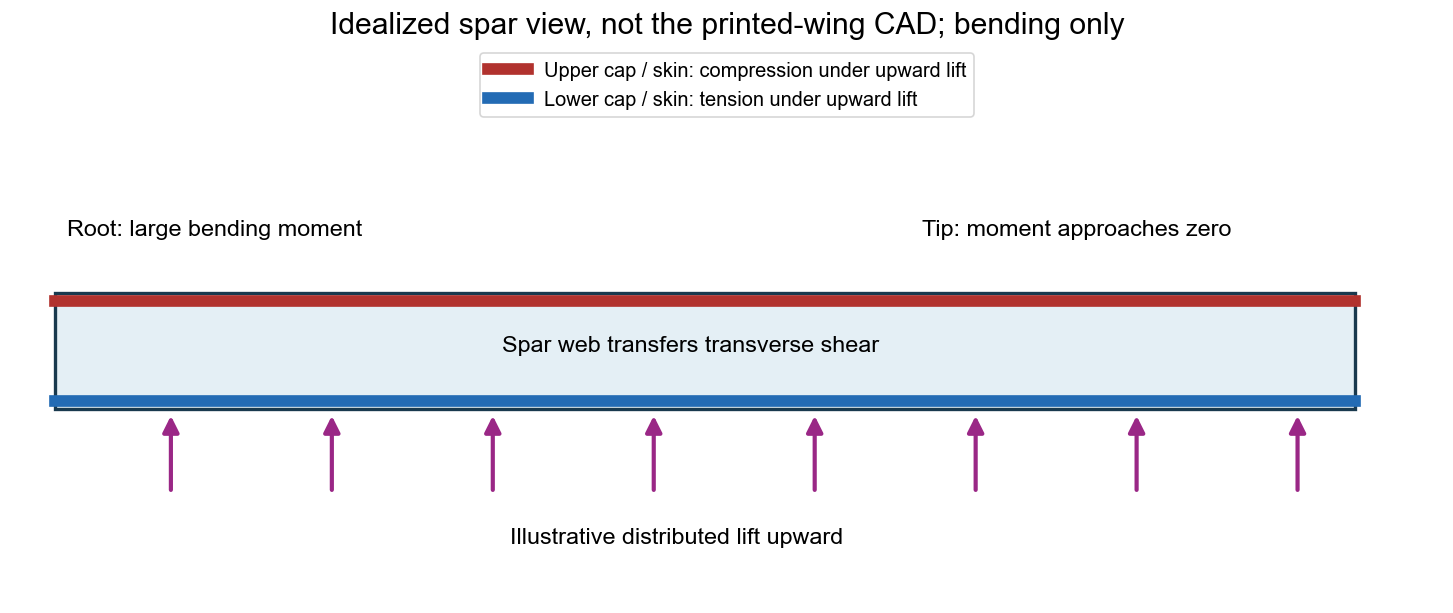

In [23]:
#@title Figure 8 — a wing spar turns bending into a separated force couple
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
ax.add_patch(Rectangle((0,0),450,30,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.plot([0,450],[28,28],color='#b1322e',lw=7,label='Upper cap / skin: compression under upward lift')
ax.plot([0,450],[2,2],color='#236bb4',lw=7,label='Lower cap / skin: tension under upward lift')
for at in np.linspace(40,430,8): arrow(ax,(at,-22),(at,-1),'#9a2786')
ax.text(215,-35,'Illustrative distributed lift upward',ha='center')
ax.text(220,15,'Spar web transfers transverse shear',ha='center',fontsize=14)
ax.text(4,45,'Root: large bending moment',fontsize=14)
ax.text(300,45,'Tip: moment approaches zero',fontsize=14)
ax.set(xlim=(-15,480),ylim=(-50,95)); ax.axis('off'); ax.legend(loc='upper center',fontsize=12)
ax.set_title('Idealized spar view, not the printed-wing CAD; bending only')
plt.show()

### Optional orientation — distinguish a bending moment from torque

Use this as a visual bridge to a wing's twisting motion, not as a new 90-minute beam exercise. A vertical force on a spanwise lever produces bending; a tangential force with offset r from the longitudinal axis produces torque about that axis:

$$T=F_t r.$$

For a straight homogeneous circular tube under Saint-Venant torsion:

$$J=\frac{\pi}{2}(R_o^4-R_i^4),\qquad
\phi=\frac{T\ell}{GJ},\qquad \tau(r)=\frac{Tr}{J}.$$

The optional figure labels ℓ, outer radius Rₒ, inner radius Rᵢ, force Fₜ, lever r, torque T, axis x and rotation φ. G is the material shear modulus; J is calculated from the cross-sectional radii. This circular-tube formula does not apply to the rectangular teaching beam or directly to a multi-cell wing box. A torsional couple is not the sagging bending moment M in the earlier formulas.

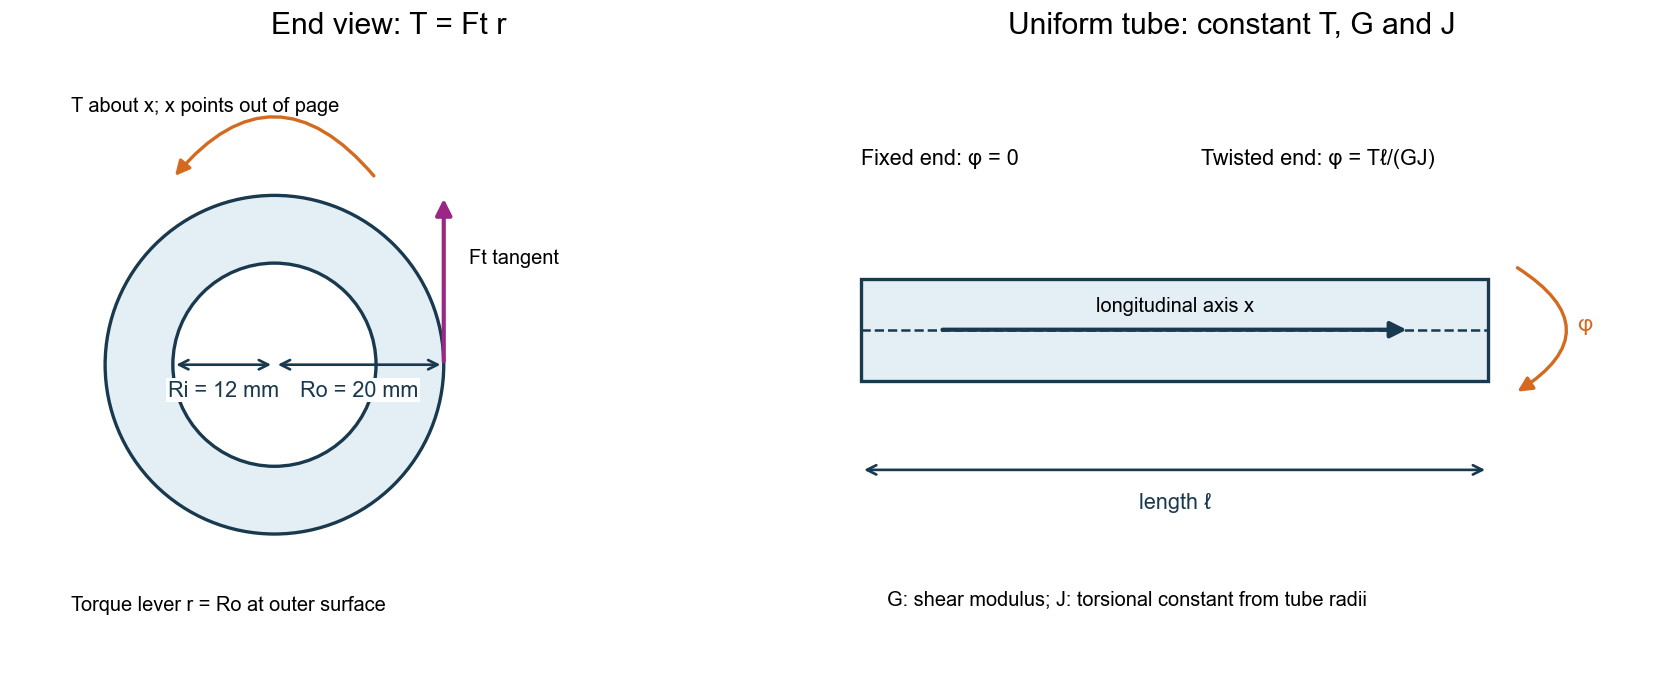

In [24]:
#@title Optional Figure 9 — torsion symbols on a circular tube, not the beam solver
fig,axes=plt.subplots(1,2,figsize=(14,5.5),layout='constrained')
ax=axes[0]
Ro,Ri=20.,12.
ax.add_patch(Circle((0,0),Ro,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.add_patch(Circle((0,0),Ri,facecolor='white',edgecolor='#19394e',lw=2))
dimension(ax,(0,0),(Ro,0),'Ro = 20 mm',(0,-3))
dimension(ax,(0,0),(-Ri,0),'Ri = 12 mm',(0,-3))
arrow(ax,(Ro,0),(Ro,20),'#9a2786');ax.text(23,12,'Ft tangent',fontsize=12)
ax.add_patch(FancyArrowPatch((12,22),(-12,22),connectionstyle='arc3,rad=.6',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(-24,30,'T about x; x points out of page',fontsize=12)
ax.text(-24,-29,'Torque lever r = Ro at outer surface',fontsize=12)
ax.set(xlim=(-31,58),ylim=(-35,38),title='End view: T = Ft r');ax.set_aspect('equal');ax.axis('off')
ax=axes[1]
ax.add_patch(Rectangle((0,-8),120,16,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.plot([0,120],[0,0],'--',color='#19394e')
dimension(ax,(0,-22),(120,-22),'length ℓ',(0,-5))
arrow(ax,(15,0),(105,0),'#19394e');ax.text(60,3,'longitudinal axis x',ha='center',fontsize=12)
ax.text(0,26,'Fixed end: φ = 0',fontsize=13)
ax.text(65,26,'Twisted end: φ = Tℓ/(GJ)',fontsize=13)
ax.add_patch(FancyArrowPatch((125,10),(125,-10),connectionstyle='arc3,rad=-.8',
                            arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(137,0,'φ',fontsize=14,color='#d46a1f')
ax.text(5,-43,'G: shear modulus; J: torsional constant from tube radii',fontsize=12)
ax.set(xlim=(-8,150),ylim=(-52,45),title='Uniform tube: constant T, G and J');ax.axis('off')
plt.show()

## 7. Four-minute exit ticket and after-class practice

Submit one page with: a labelled free body; reaction unknowns and constraints; one equilibrium check; one moment-to-stress calculation; one deflection calculation; the app study record; and a sentence explaining the largest stress and displacement locations. Use units on every numerical result.

1. Why is root displacement zero while root stress can be largest?
2. Why do two 2 N loads have different moments and deflections?
3. Which extra information is needed for a fixed–fixed beam beyond equilibrium?
4. If an app returns zero deflection, where was the load placed and what motions were restrained?

**After class, not part of the 90-minute route:** change one parameter at a time. Predict and test P×2, E×2 and h×2. Then explore the triangle/trapezoid options from Lecture 02, keeping total force fixed. Reactions and stress checks should precede vibration modes.

### Reading and model scope

[TU Delft beam theory and finite elements](https://teachbooks.tudelft.nl/computational-modelling/structural_linear/euler_bernouilli.html) supports the equilibrium–curvature–boundary-condition framework. Our diagrams are original instructional illustrations. Numerical examples use declared assumed dimensions/material values and closed-form elastic beam solutions, independently checked against the course beam engine. Scope: straight, slender, homogeneous solid section; constant EI; ideal supports; linear elasticity and small displacement; no self-weight unless specified. This is not an airworthiness or printed-wing failure certification.